# Restart Criterion. 
In this notebook we will follow the following workflow:

 - Dataset of Assets, properties, correlation, etc.
 - Presentation of restart strategy.
    - Presentation of Used Metrics.
        - Kendall's tau.
        - Weighted Kendall's tau.
        - Blest ranking coefficient.
    - Comparison so we can see the characteristics of this metrics.
- Results of the restart strategy.
- Optimization of Variables:
    - Divisition of Dataset.
    - $\mu$ and $\lambda$.
    - Optimizing of the threshold.
    - Validation of parameters.

In [1]:
# %%
import pandas as pd
import numpy as np
import yfinance as yf
from matplotlib.ticker import MaxNLocator
from VB_FTRL import VB_FTRL
import price as price
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
from scipy.stats import kendalltau, weightedtau
from Blest import blest_coeff
from aggresive_tau import aggressive_weightedtau
import scoring


In [2]:
# Download historical data from 2010 to 2025
data = pd.read_csv('data/normalized_prices.csv',parse_dates=['Date'])
data.set_index('Date', inplace=True)

## Real Data Used

We selected the following data because as we may see in the following code is uncorrelated, that will allow us to study without bias the correct working of our algorithm. In this case we take a 48 different assets.

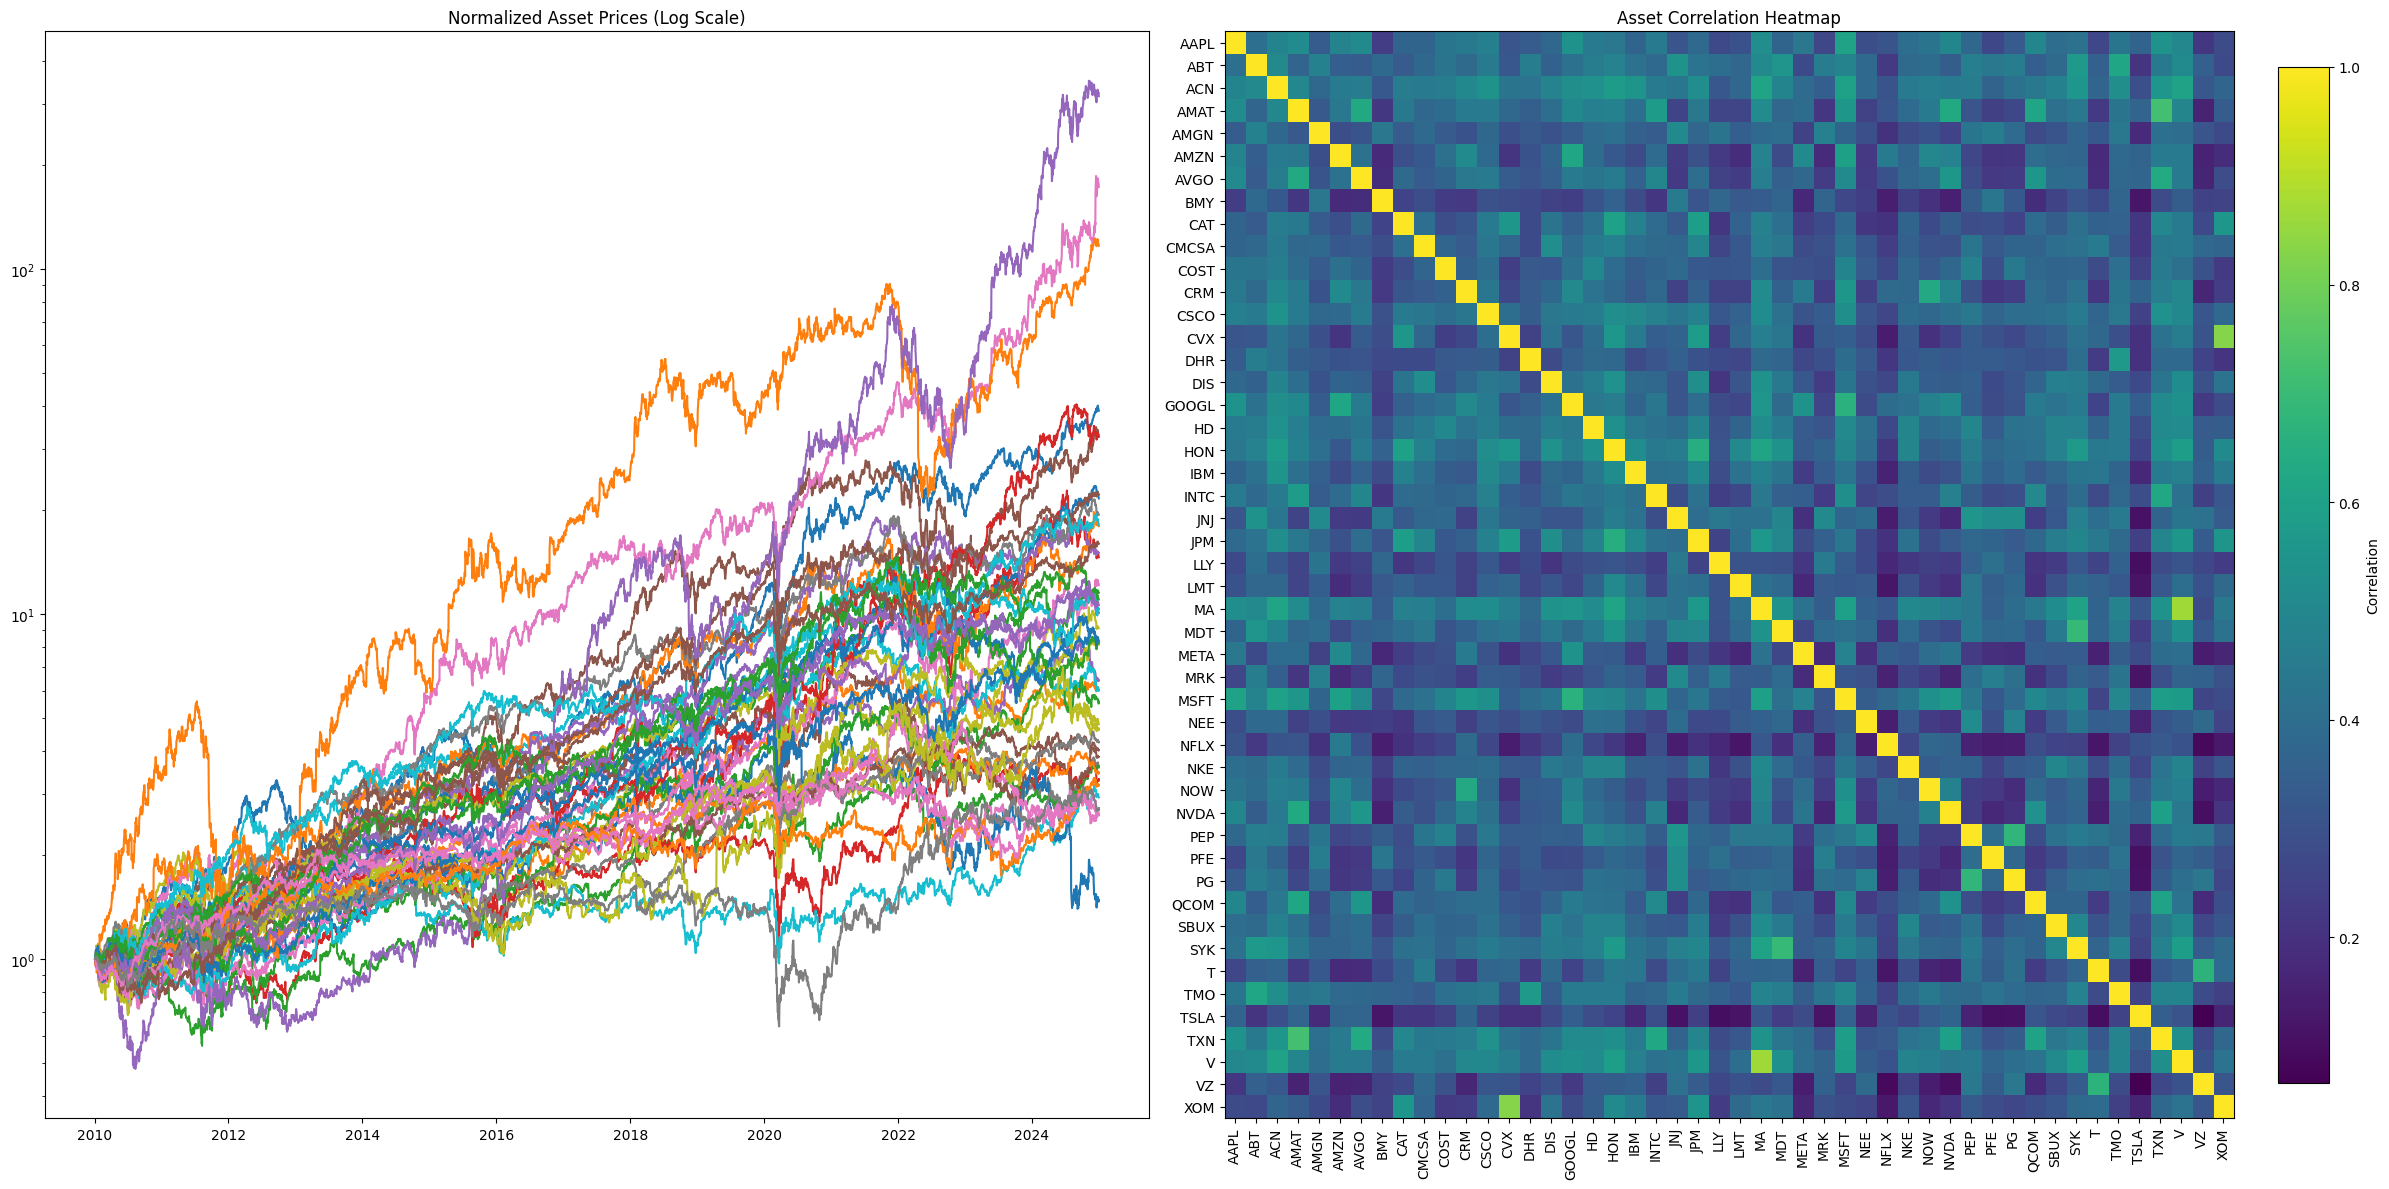

In [3]:
# Compute returns & correlation
returns = data.pct_change().dropna()
corr = returns.corr()

# Normalize prices (base = 1)
data_normalized = data / data.iloc[0]

# Create side-by-side subplots
fig, axes = plt.subplots(1, 2, figsize=(24, 12))

# — Left: normalized prices (log scale)
axes[0].plot(data_normalized.index, data_normalized.values)
axes[0].set_title("Normalized Asset Prices (Log Scale)")
axes[0].set_yscale('log')

# — Right: correlation heatmap
cax = axes[1].imshow(
    corr,
    interpolation='nearest',
    aspect='auto'
)
axes[1].set_title("Asset Correlation Heatmap")
axes[1].set_xticks(range(len(corr.columns)))
axes[1].set_xticklabels(corr.columns, rotation=90)
axes[1].set_yticks(range(len(corr.index)))
axes[1].set_yticklabels(corr.index)
fig.colorbar(cax, ax=axes[1], fraction=0.046, pad=0.04, label='Correlation')

plt.tight_layout()
plt.show()


## Interest of Restart

As we may see, in the following example, the weights of VB-FTRL-qN algorithm converge after a period of time, thus making it unsensible to new market conditions. This could potentially mean loses that could be perfectly avoidable with a restart. For this example we will study the case of the Top 5 Winners and Losers of the Covid Crisis. 


In [4]:
# Download historical data from 2018 to 2025
# Load the full 2010–2025 data
data_covid = pd.read_csv('data/covid_data.csv', parse_dates=['Date'])
data_covid.set_index('Date', inplace=True)

# Keep only data from 2018-01-01 onward
data_covid = data_covid.loc['2018-01-01':]


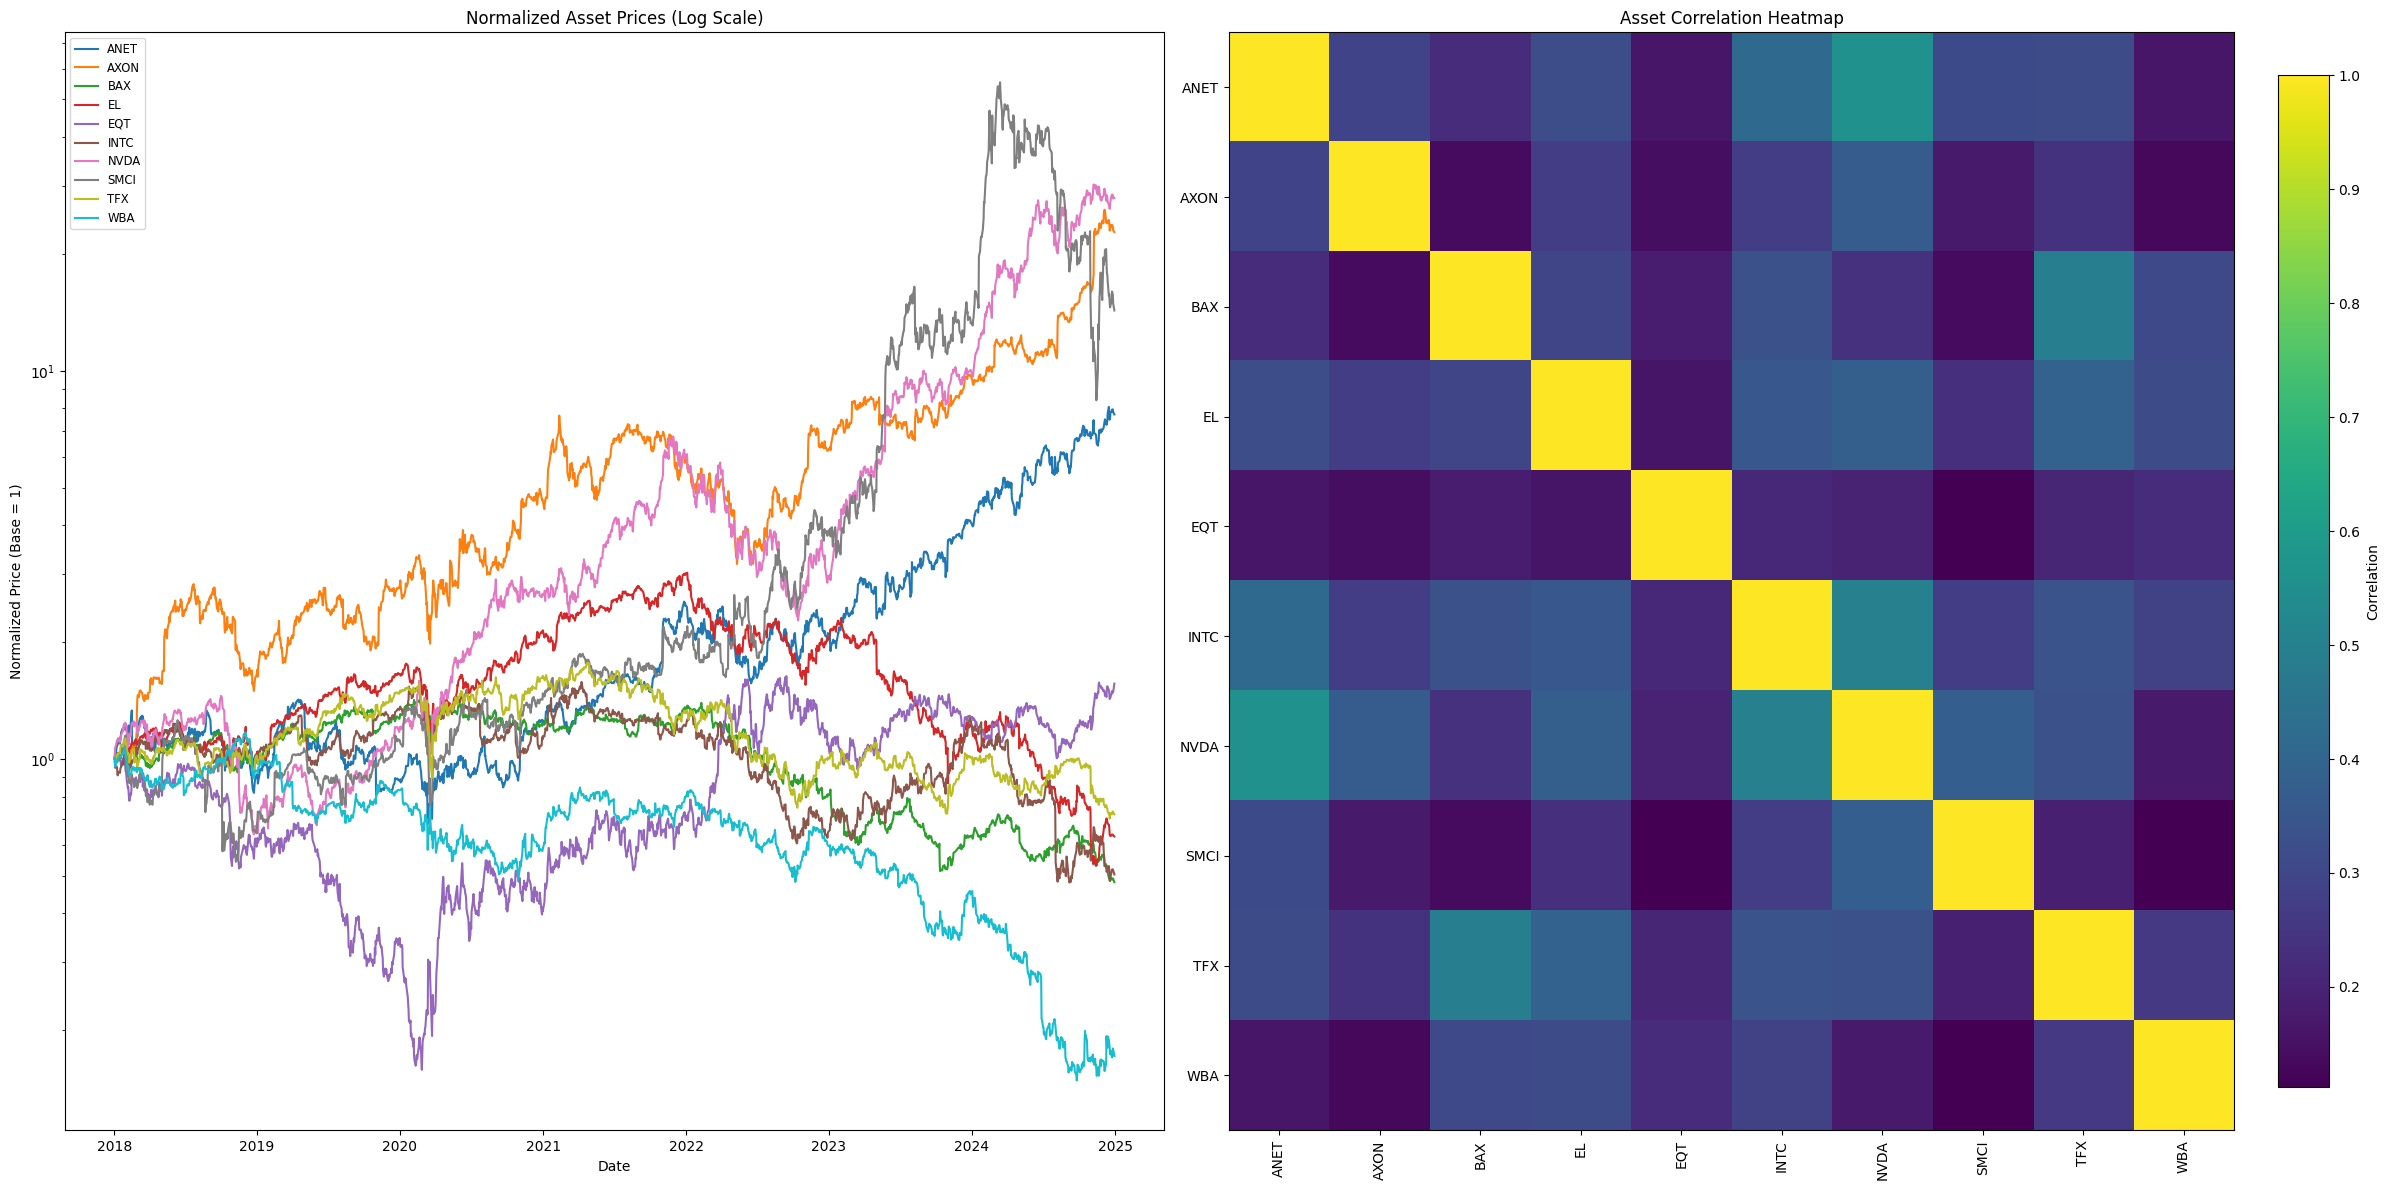

In [5]:
# Compute daily percentage returns and drop the first NA row
returns_covid = data_covid.pct_change().dropna()

# Compute the correlation matrix of all tickers
corr_covid = returns_covid.corr()

# ----------------------------------------
# Part 3: Normalize prices (base = 1 at first date)
# ----------------------------------------

# Divide each column by its value on the first available date
data_covid_normalized = data_covid / data_covid.iloc[0]

# ----------------------------------------
# Part 4: Plot normalized prices and correlation heatmap, with tickers labeled
# ----------------------------------------

# Create side-by-side subplots
fig, axes = plt.subplots(1, 2, figsize=(24, 12))

# — Left subplot: normalized prices (log scale)
for ticker in data_covid_normalized.columns:
    axes[0].plot(
        data_covid_normalized.index,
        data_covid_normalized[ticker],
        label=ticker
    )
axes[0].set_title("Normalized Asset Prices (Log Scale)")
axes[0].set_yscale('log')
axes[0].legend(loc='upper left', fontsize='small')
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Normalized Price (Base = 1)")

# — Right subplot: correlation heatmap
cax = axes[1].imshow(
    corr_covid.values,
    interpolation='nearest',
    aspect='auto',
)
axes[1].set_title("Asset Correlation Heatmap")
axes[1].set_xticks(range(len(corr_covid.columns)))
axes[1].set_xticklabels(corr_covid.columns, rotation=90)
axes[1].set_yticks(range(len(corr_covid.index)))
axes[1].set_yticklabels(corr_covid.index)
fig.colorbar(cax, ax=axes[1], fraction=0.046, pad=0.04, label='Correlation')

# Adjust layout and show the figure
plt.tight_layout()
plt.show()

We as humans would have detected intuitively the market change regime in order to adapt our portfolio to new "winners". But as mentioned before, and from what we can see on the weights plot, this algorithm does not adapt to this new conditions. Nevertheless let's see what would happen if we would have "restarted" the algorithm after the first month of lockdown April of 2020. 

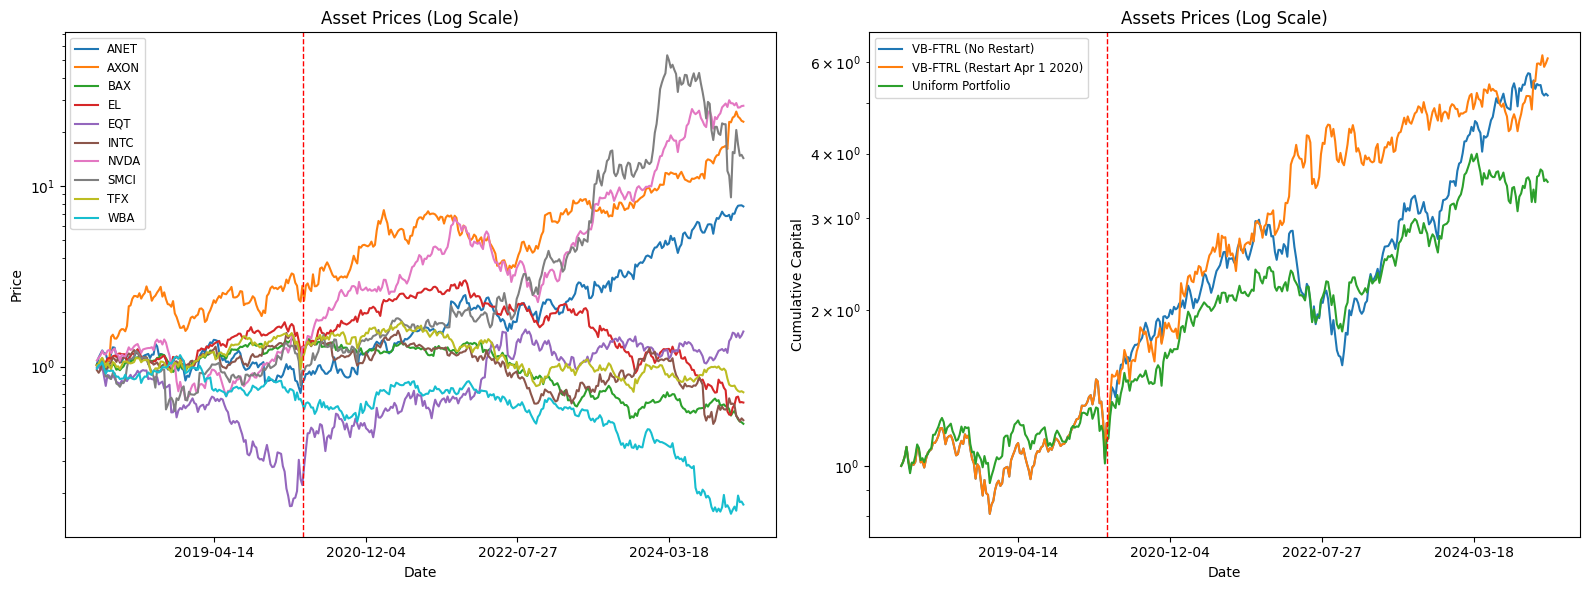

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# ----------------------------------------
# 1) Prepare your data: 'prix' is your price DataFrame
# ----------------------------------------
prix = data_covid_normalized.ffill().bfill().dropna(axis=1)
prix_weekly = prix.resample('W').last()
returns_weekly = prix_weekly.pct_change().iloc[1:]
rescaled_weekly = price.rescale(returns_weekly, method="minmax", threshold=0.09)

n_assets = returns_weekly.shape[1]
Tw = prix_weekly.shape[0]

# ----------------------------------------
# 2) Initialize capital arrays
# ----------------------------------------
capital_no_restart = np.zeros(Tw)
capital_no_restart[0] = 1.0

capital_restart_apr2020 = np.zeros(Tw)
capital_restart_apr2020[0] = 1.0

capital_uniform = np.zeros(Tw)
capital_uniform[0] = 1.0

# ----------------------------------------
# 3) Instantiate algorithms
# ----------------------------------------
# No‐restart VB‐FTRL
algo_no_restart = VB_FTRL(
    n_assets,
    mu=0.2,
    lambda_val=0.2,
    threshold=-1.0,                  # disable automatic restarts
    scoring_func=scoring.historic_returns
)

# Restart‐on‐April‐1‐2020 VB‐FTRL (we’ll trigger restart manually)
algo_restart_apr2020 = VB_FTRL(
    n_assets,
    mu=0.2,
    lambda_val=0.2,
    threshold=-1.0,                  # disable automatic restarts
    scoring_func=scoring.historic_returns
)

# ----------------------------------------
# 4) Keep track of weights for plotting
# ----------------------------------------
pastw_no = [algo_no_restart.w.copy()]
pastw_restart_apr2020 = [algo_restart_apr2020.w.copy()]

# Flag to ensure we only restart once, on or after April 1, 2020
restart_done = False
restart_date = pd.Timestamp('2020-04-01')

# ----------------------------------------
# 5) Weekly backtest loop
# ----------------------------------------
for t in range(Tw - 1):
    # Current calendar date (weekly label)
    date_t = prix_weekly.index[t]
    
    # 5a) Compute uniform‐weight strategy
    r = returns_weekly.iloc[t].values  # actual return vector for this week
    capital_uniform[t + 1] = capital_uniform[t] * (np.sum(r + 1) / n_assets)
    
    # 5b) No‐restart VB‐FTRL
    w_nr = algo_no_restart.w.copy()
    capital_no_restart[t + 1] = capital_no_restart[t] * np.dot(w_nr, (r + 1))
    algo_no_restart.update(rescaled_weekly.iloc[t].values)
    algo_no_restart.w[algo_no_restart.w < 0] = 0.1
    algo_no_restart.w /= np.linalg.norm(algo_no_restart.w, 1)
    pastw_no.append(algo_no_restart.w.copy())
    
    # 5c) Restart‐on‐April‐1‐2020 VB‐FTRL
    #    Trigger a manual restart at the first week on or after April 1, 2020
    if (not restart_done) and (date_t >= restart_date) and (t > 0):
        prev_index = t - 1
        prev_return = returns_weekly.iloc[prev_index].values
        algo_restart_apr2020.restart(prev_return, prev_index)
        restart_done = True
        # Overwrite weight at time t with the freshly‐restarted portfolio
        pastw_restart_apr2020[t] = algo_restart_apr2020.w.copy()

    # Compute capital for the restart‐Apr2020 strategy using the current weight
    w_ra = algo_restart_apr2020.w.copy()
    capital_restart_apr2020[t + 1] = capital_restart_apr2020[t] * np.dot(w_ra, (r + 1))
    
    # Now update algo_restart_apr2020 for next period
    algo_restart_apr2020.update(rescaled_weekly.iloc[t].values)
    algo_restart_apr2020.w[algo_restart_apr2020.w < 0] = 0.1
    algo_restart_apr2020.w /= np.linalg.norm(algo_restart_apr2020.w, 1)
    pastw_restart_apr2020.append(algo_restart_apr2020.w.copy())

# ----------------------------------------
# 6) Plotting
# ----------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# — Left subplot: weekly asset prices (log scale) with tickers
for ticker in prix_weekly.columns:
    axes[0].plot(prix_weekly.index, prix_weekly[ticker], label=ticker)
axes[0].set_title("Asset Prices (Log Scale)")
axes[0].set_yscale('log')
axes[0].xaxis.set_major_locator(MaxNLocator(nbins=5))
# Add vertical dotted red line at the restart date
axes[0].axvline(x=restart_date, color='red', linestyle='--', linewidth=1)
axes[0].legend(loc='upper left', fontsize='small')
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Price")

# — Right subplot: cumulative capital trajectories (log scale)
axes[1].plot(prix_weekly.index, capital_no_restart, label='VB-FTRL (No Restart)')
axes[1].plot(prix_weekly.index, capital_restart_apr2020, label='VB-FTRL (Restart Apr 1 2020)')
axes[1].plot(prix_weekly.index, capital_uniform, label='Uniform Portfolio')
axes[1].set_title("Assets Prices (Log Scale)")
axes[1].set_yscale('log')
axes[1].xaxis.set_major_locator(MaxNLocator(nbins=5))
# Add vertical dotted red line at the restart date
axes[1].axvline(x=restart_date, color='red', linestyle='--', linewidth=1)
axes[1].legend(fontsize='small')
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Cumulative Capital")

plt.tight_layout()
plt.show()



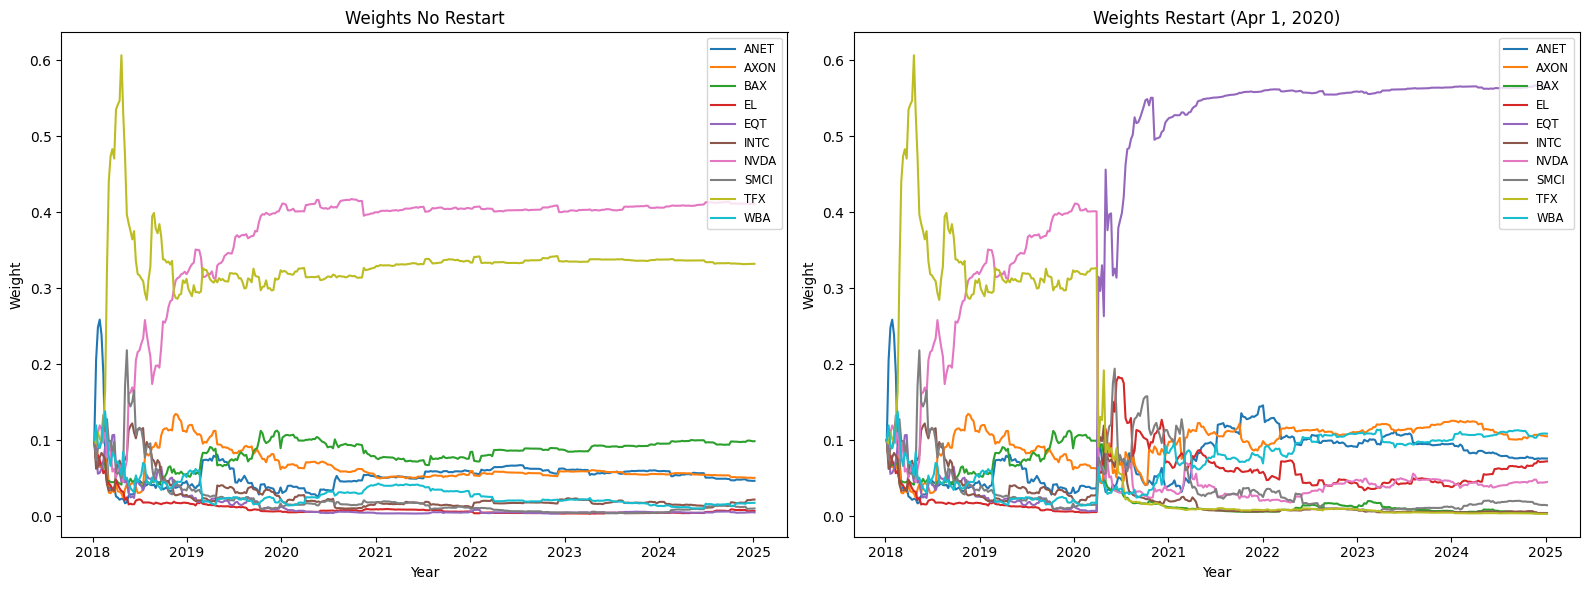

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Convert weight histories to NumPy arrays
weights_no = np.array(pastw_no)
weights_restart = np.array(pastw_restart_apr2020)

# Create a figure with two subplots side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True)

# — Left subplot: Weights No Restart
for idx, ticker in enumerate(prix_weekly.columns):
    axes[0].plot(
        prix_weekly.index,
        weights_no[:, idx],
        label=ticker
    )
axes[0].set_title("Weights No Restart")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Weight")
axes[0].legend(loc='upper right', fontsize='small')
axes[0].xaxis.set_major_locator(mdates.YearLocator())
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.setp(axes[0].get_xticklabels(), rotation=0, ha='center')

# — Right subplot: Weights Restart (Apr 1, 2020)
for idx, ticker in enumerate(prix_weekly.columns):
    axes[1].plot(
        prix_weekly.index,
        weights_restart[:, idx],
        label=ticker
    )
axes[1].set_title("Weights Restart (Apr 1, 2020)")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Weight")
axes[1].legend(loc='upper right', fontsize='small')
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.setp(axes[1].get_xticklabels(), rotation=0, ha='center')

plt.tight_layout()
plt.show()



## Restart Strategy

One of the problems that VB-FTRL-qN can find is once it has converged, in a certain way it loses its "Sensitivity" throughout time, since it minimizes the accumulated regret. So let's consider the case when the algorithm have converged, if there is a market regime change, the algorithm won't be able to adapt to this new conditions, meaning potential losses in terms of capital. 

In order to detect this market changes, what we do is the following, at time-step $t$

- Rank the Stocks for periods $t-1$ and $t-2$, wrt a certain performance metric (Ex: Returns, 1m-Returns, 1w-Returns, Sharpe-Ratio, Volatility).
- We calculate the Ranking Correlation between the two. We will denote it $r_{t-2\mapsto t-1}$. We will use 3 different metrics: Kendall's Tau, Weighted Tau, Blest Coefficient.
- If the Correlation between the two periods is under the threshold (sufficiently different), we restart the algorithm.
    - In order to exploit the information we do a simulation of the weights at time $t$ if we would have restarted at time $t-1$ with the equidistributed portfolio.
    - With the weights obtained from the simulation we go on with the algorithm.


### Ranking Correlation Metrics


### Kendall's τ

**Definition:**  
For a set of $n$ paired observations $(x_i, y_i)$, Kendall’s τ is defined as:  
$
  τ = \frac{n_c - n_d}{\binom{n}{2}} = \frac{2(n_c - n_d)}{n(n-1)},
$
where  
- $n_c$ = number of concordant pairs  
- $n_d$ = number of discordant pairs  

**Characteristics:**  
- **Range:** $[-1,1]$: 1 perfect agreement, –1 perfect disagreement, 0 no association.  
- **Nature:** Non-parametric, robust to outliers.  
- **Weighting:** All pairs treated equally.  

---

### Weighted Kendall's τ_w

**Definition:**  
$
  τ_w = \frac{\sum_{i<j} w_{ij}\,\mathrm{sgn}\bigl[(R_i-R_j)(S_i-S_j)\bigr]}{\sum_{i<j} w_{ij}},
$
with symmetric weights $w_{ij}$ (e.g.\ hyperbolic: $w_{ij}=1/(i+j)$).  

**Characteristics:**  
- **Range:** $[-1,1]$, same interpretation as τ.  
- **Emphasis:** Highlights agreement/disagreement in specified rank regions (e.g.\ top items).  
- **Flexibility:** Choose weight function to tailor sensitivity.  

---

### Blest Ranking Correlation Coefficient (νₙ)

**Definition:**  
For two lists of ranks $\{R_i\}$ and $\{S_i\}$ over $n$ items, the Blest coefficient is
$
  ν_n
  = \frac{2n+1}{\,n-1\,}
  \;-\;
  \frac{12}{\,n^2 - n\,}
  \sum_{i=1}^n
    \Bigl(1 - \tfrac{R_i}{n+1}\Bigr)^{2}\,S_i.
$

**Characteristics:**  
- **Range:** $[-1,1]$.  
- **Sensitivity:** Quadratic weight $\bigl(1 - \tfrac{R_i}{n+1}\bigr)^2$ makes large shifts in individual positions (especially near the top) disproportionately impactful.  
- **Use case:** Ideal when agreement at the head of the ranking is most critical.  


In [8]:
### Hands on example for comparison
A = [1, 2, 3, 4, 5, 6, 7, 8, 9]
B = [1, 2, 3, 9, 8, 7, 6, 4, 5]
C = [5, 6, 4, 3, 2, 1, 7, 8, 9]

In [9]:
### Ranking Correlation Obtained Values

print("--------------Ranking Correlation Obtained Values-----------------")
print("\n")
print("------------------Kendall tau correlation------------------")
print(f" Kendall tau correlation between A and B: {kendalltau(A,B)[0]} ")
print(f" Kendall tau correlation between A and C: {kendalltau(A,C)[0]} ")
print("\n")
print("------------------Weighted Kendall tau correlation------------------")
print(f" Weighted Kendall tau correlation between A and B: {kendalltau(A,B)[0]} ")
print(f" Weighted Kendall tau correlation between A and C: {kendalltau(A,C)[0]} ")
print("\n")
print("------------------Blest Correlation------------------")
print(f" Blest correlation between A and B: {blest_coeff(A,B)} ")
print(f" Blest correlation between A and C: {blest_coeff(A,C)} ")

--------------Ranking Correlation Obtained Values-----------------


------------------Kendall tau correlation------------------
 Kendall tau correlation between A and B: 0.2222222222222222 
 Kendall tau correlation between A and C: 0.2222222222222222 


------------------Weighted Kendall tau correlation------------------
 Weighted Kendall tau correlation between A and B: 0.2222222222222222 
 Weighted Kendall tau correlation between A and C: 0.2222222222222222 


------------------Blest Correlation------------------
 Blest correlation between A and B: 0.5966666666666667 
 Blest correlation between A and C: 0.27 


## Results of the Algorithm with Restart

In [10]:
# Assuming VB_FTRL_restart is defined and imported, with internal restart logic based on threshold

# 1) Prepare your data: 'prix' is your price DataFrame
prix = data_normalized.ffill().bfill().dropna(axis=1)
prix_weekly = prix.resample('W').last()
returns_weekly = prix_weekly.pct_change().iloc[1:]
rescaled_weekly = price.rescale(returns_weekly, method="minmax", threshold=0.09)

n_assets = returns_weekly.shape[1]
Tw = prix_weekly.shape[0]

# 2) Initialize capital arrays
capital_no_restart = np.zeros(Tw); capital_no_restart[0] = 1.0
capital_restart_kendall    = np.zeros(Tw); capital_restart_kendall[0]    = 1.0
capital_restart_weighted_kendall = np.zeros(Tw); capital_restart_weighted_kendall[0] = 1.0
capital_restart_blest    = np.zeros(Tw); capital_restart_blest[0]    = 1.0
capital_uniform    = np.zeros(Tw); capital_uniform[0]    = 1.0

# 3) Instantiate algorithms
algo_no_restart = VB_FTRL(n_assets, mu=0.2, lambda_val=0.2, threshold=-1.0, scoring_func=scoring.historic_returns)  # threshold < -1 so never restarts
algo_restart_kendall   = VB_FTRL(n_assets, mu=0.2, lambda_val=0.2, threshold= -0.2, corr_func=kendalltau, scoring_func=scoring.historic_returns)   # restart when tau < 0
algo_restart_weighted_kendall = VB_FTRL(n_assets, mu=0.2, lambda_val=0.2, threshold=-0.2, corr_func=weightedtau, scoring_func=scoring.historic_returns)  # restart when tau < 0
algo_restart_blest   = VB_FTRL(n_assets, mu=0.2, lambda_val=0.2, threshold= -0.2, corr_func=blest_coeff, scoring_func=scoring.historic_returns)   # restart when tau < 0

# 4) Keep track of weights for plotting
pastw_no = [algo_no_restart.w.copy()]
pastw_restart_kendall = [algo_restart_kendall.w.copy()]
pastw_restart_weighted_kendall = [algo_restart_weighted_kendall.w.copy()]
pastw_restart_blest = [algo_restart_blest.w.copy()]

# 5) Weekly backtest loop
for t in range(Tw-1):
    # actual return vector
    r = returns_weekly.iloc[t].values

    # Uniform strategy
    capital_uniform[t+1] = capital_uniform[t] * (np.sum(r + 1) / n_assets)

    # No-restart algorithm
    w_nr = algo_no_restart.w.copy()
    capital_no_restart[t+1] = capital_no_restart[t] * np.dot(w_nr, r + 1)
    # update on the raw features (rescaled returns)
    algo_no_restart.update(rescaled_weekly.iloc[t].values)
    # enforce positivity and simplex
    algo_no_restart.w[algo_no_restart.w < 0] = 0.1
    algo_no_restart.w /= np.linalg.norm(algo_no_restart.w, 1)
    pastw_no.append(algo_no_restart.w.copy())

    # Kendall restart algorithm
    w_restart_k = algo_restart_kendall.w.copy()
    capital_restart_kendall[t+1] = capital_restart_kendall[t] * np.dot(w_restart_k, r + 1)
    algo_restart_kendall.update(rescaled_weekly.iloc[t].values)
    algo_restart_kendall.w[algo_restart_kendall.w < 0] = 0.1
    algo_restart_kendall.w /= np.linalg.norm(algo_restart_kendall.w, 1)
    pastw_restart_kendall.append(algo_restart_kendall.w.copy())
    # Weighted Kendall restart algorithm
    w_restart_wk = algo_restart_weighted_kendall.w.copy()
    capital_restart_weighted_kendall[t+1] = capital_restart_weighted_kendall[t] * np.dot(w_restart_wk, r + 1)
    algo_restart_weighted_kendall.update(rescaled_weekly.iloc[t].values)
    algo_restart_weighted_kendall.w[algo_restart_weighted_kendall.w < 0] = 0.1
    algo_restart_weighted_kendall.w /= np.linalg.norm(algo_restart_weighted_kendall.w, 1)
    pastw_restart_weighted_kendall.append(algo_restart_weighted_kendall.w.copy())
    # Blest restart algorithm
    w_restart_b = algo_restart_blest.w.copy()
    capital_restart_blest[t+1] = capital_restart_blest[t] * np.dot(w_restart_b, r + 1)
    algo_restart_blest.update(rescaled_weekly.iloc[t].values)
    algo_restart_blest.w[algo_restart_blest.w < 0] = 0.1
    algo_restart_blest.w /= np.linalg.norm(algo_restart_blest.w, 1)
    pastw_restart_blest.append(algo_restart_blest.w.copy())

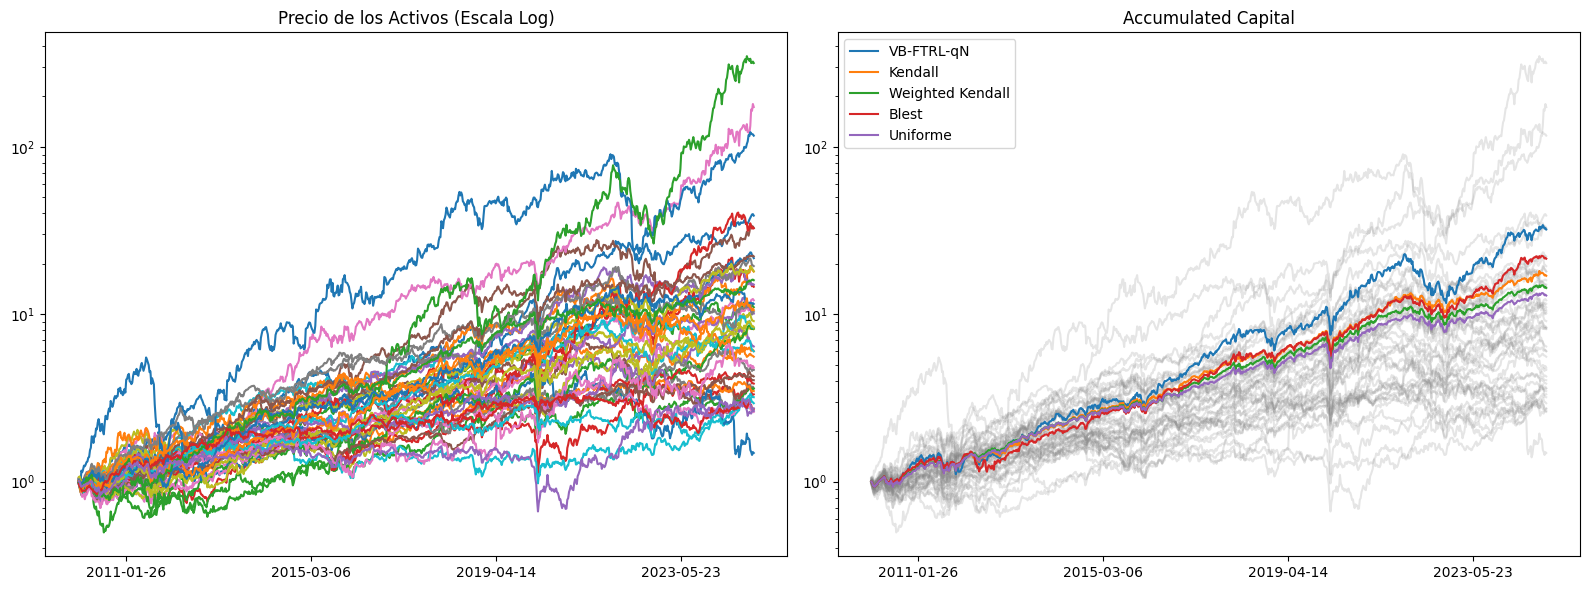

In [11]:
# 6) Plotting
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Asset prices (log scale)
axes[0].plot(prix_weekly.index, prix_weekly.values)
axes[0].set_title("Precio de los Activos (Escala Log)")
axes[0].set_yscale('log')
axes[0].xaxis.set_major_locator(MaxNLocator(nbins=5))

# Cumulative capital
axes[1].plot(prix_weekly.index, prix_weekly.values, color='gray', alpha=0.2)
axes[1].plot(prix_weekly.index, capital_no_restart, label='VB-FTRL-qN')
axes[1].plot(prix_weekly.index, capital_restart_kendall,    label='Kendall')
axes[1].plot(prix_weekly.index, capital_restart_weighted_kendall,    label='Weighted Kendall')
axes[1].plot(prix_weekly.index, capital_restart_blest,    label='Blest')
axes[1].plot(prix_weekly.index, capital_uniform,    label='Uniforme')
axes[1].set_title("Accumulated Capital")
axes[1].set_yscale('log')
axes[1].legend()
axes[1].xaxis.set_major_locator(MaxNLocator(nbins=5))


plt.tight_layout()
plt.show()

C:\Users\Javier Toro B\AppData\Local\Temp\ipykernel_8296\765025756.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Final Capital', y='Strategy', data=final_capital_df, palette='viridis')


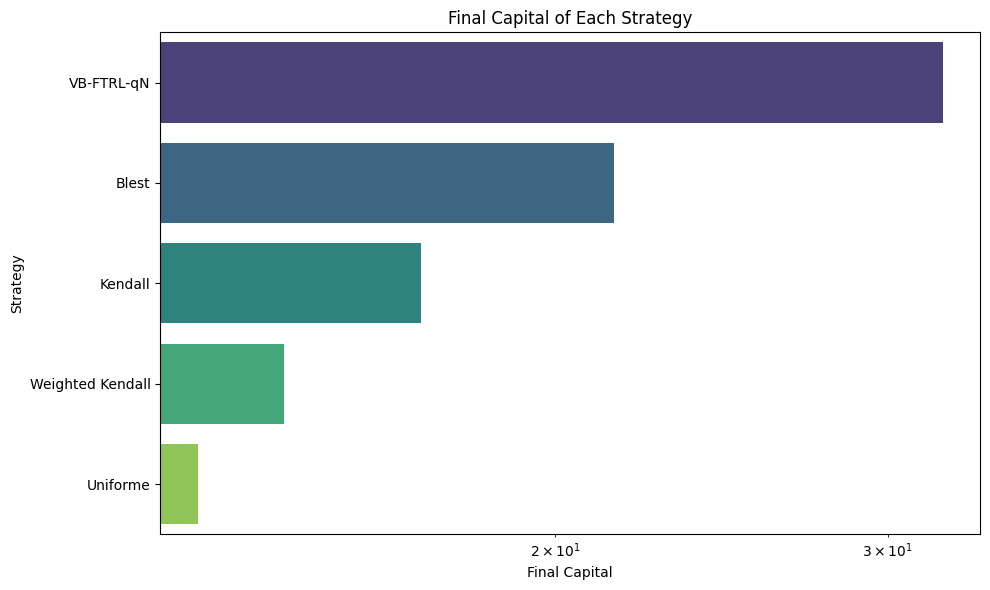

In [12]:
# We do a bar plot of the final capital of each strategy
final_capital = {
    'VB-FTRL-qN': capital_no_restart[-1],
    'Kendall': capital_restart_kendall[-1],
    'Weighted Kendall': capital_restart_weighted_kendall[-1],
    'Blest': capital_restart_blest[-1],
    'Uniforme': capital_uniform[-1]
}
final_capital_df = pd.DataFrame(list(final_capital.items()), columns=['Strategy', 'Final Capital'])
final_capital_df = final_capital_df.sort_values(by='Final Capital', ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='Final Capital', y='Strategy', data=final_capital_df, palette='viridis')
ax.set_title("Final Capital of Each Strategy")
ax.set_xscale('log')
plt.tight_layout()
plt.show()


C:\Users\Javier Toro B\AppData\Local\Temp\ipykernel_8296\2927345264.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='upper right', fontsize='small')


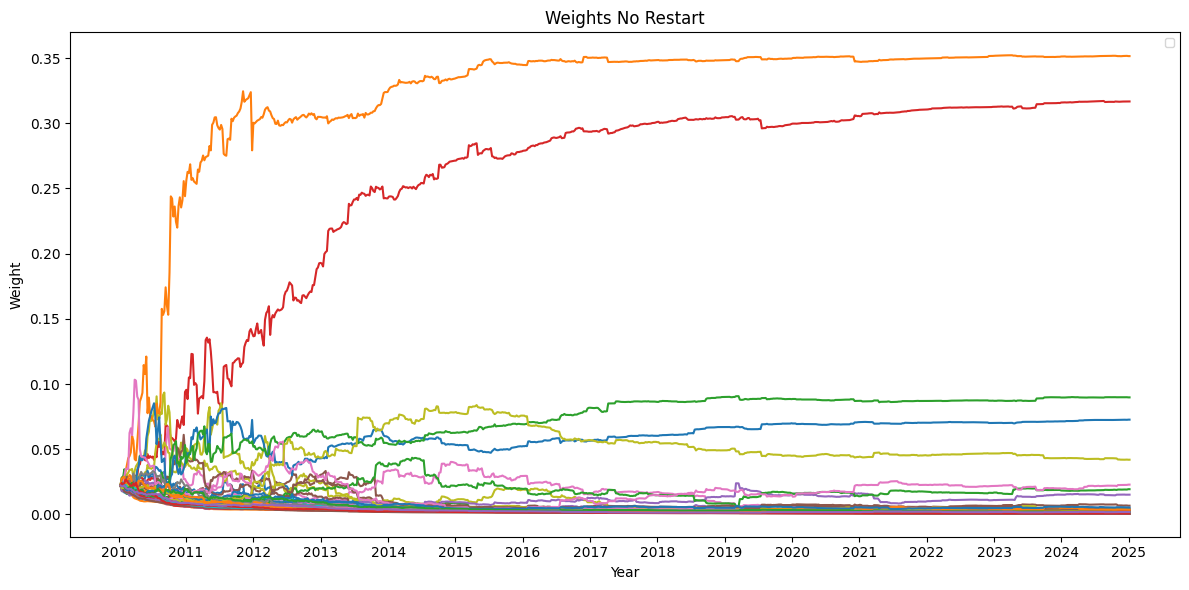

In [13]:
# Convert weight history to NumPy array
weights_no = np.array(pastw_no)

fig, ax = plt.subplots(figsize=(12, 6))

# Plot each asset’s weight over time using actual weekly timestamps
for idx, ticker in enumerate(prix_weekly.columns):
    ax.plot(
        prix_weekly.index,
        weights_no[:, idx]
    )

ax.set_title("Weights No Restart")
ax.set_xlabel("Year")
ax.set_ylabel("Weight")

# Show only the year on the x-axis (at the first week of each year)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.setp(ax.get_xticklabels(), rotation=0, ha='center')

ax.legend(loc='upper right', fontsize='small')
plt.tight_layout()
plt.show()

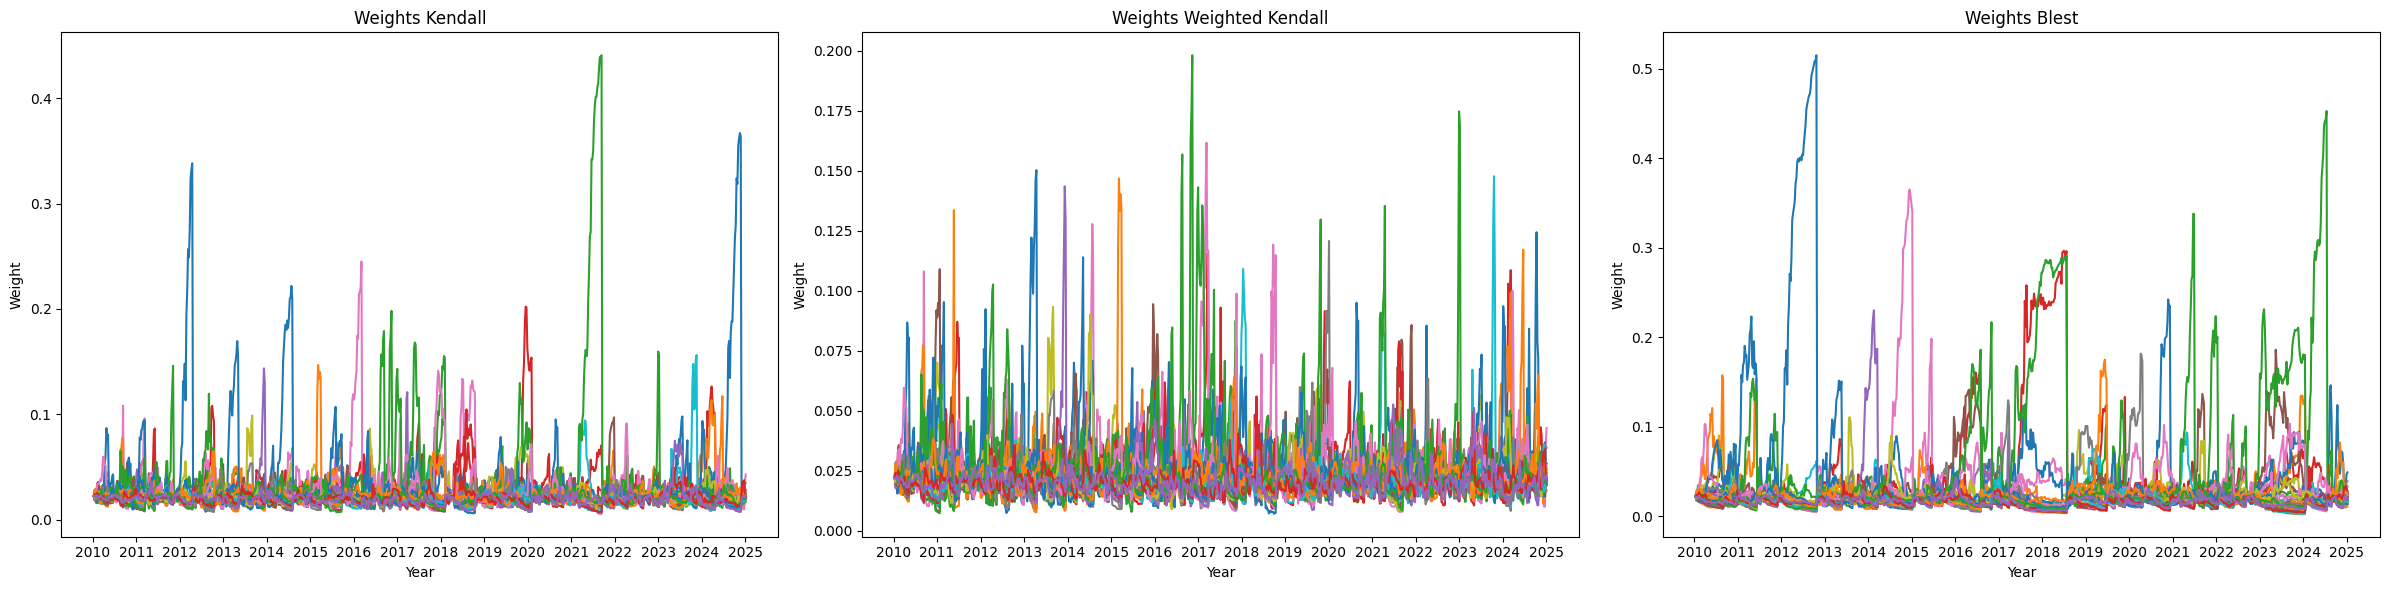

In [14]:
import matplotlib.dates as mdates

# Convert weight histories to NumPy arrays
weights_kendall = np.array(pastw_restart_kendall)
weights_wkendall = np.array(pastw_restart_weighted_kendall)
weights_blest = np.array(pastw_restart_blest)

fig, axes = plt.subplots(1, 3, figsize=(24, 6), sharex=True)

# — Left subplot: Weights Kendall
axes[0].plot(prix_weekly.index, weights_kendall)
axes[0].set_title("Weights Kendall")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Weight")
axes[0].xaxis.set_major_locator(mdates.YearLocator())
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.setp(axes[0].get_xticklabels(), rotation=0, ha='center')

# — Middle subplot: Weights Weighted Kendall
axes[1].plot(prix_weekly.index, weights_wkendall)
axes[1].set_title("Weights Weighted Kendall")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Weight")
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.setp(axes[1].get_xticklabels(), rotation=0, ha='center')

# — Right subplot: Weights Blest
axes[2].plot(prix_weekly.index, weights_blest)
axes[2].set_title("Weights Blest")
axes[2].set_xlabel("Year")
axes[2].set_ylabel("Weight")
axes[2].xaxis.set_major_locator(mdates.YearLocator())
axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.setp(axes[2].get_xticklabels(), rotation=0, ha='center')

plt.tight_layout()
plt.show()


C:\Users\Javier Toro B\AppData\Local\Temp\ipykernel_8296\3781013038.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Number of Restarts', y='Strategy', data=n_restarts_df, palette='viridis')


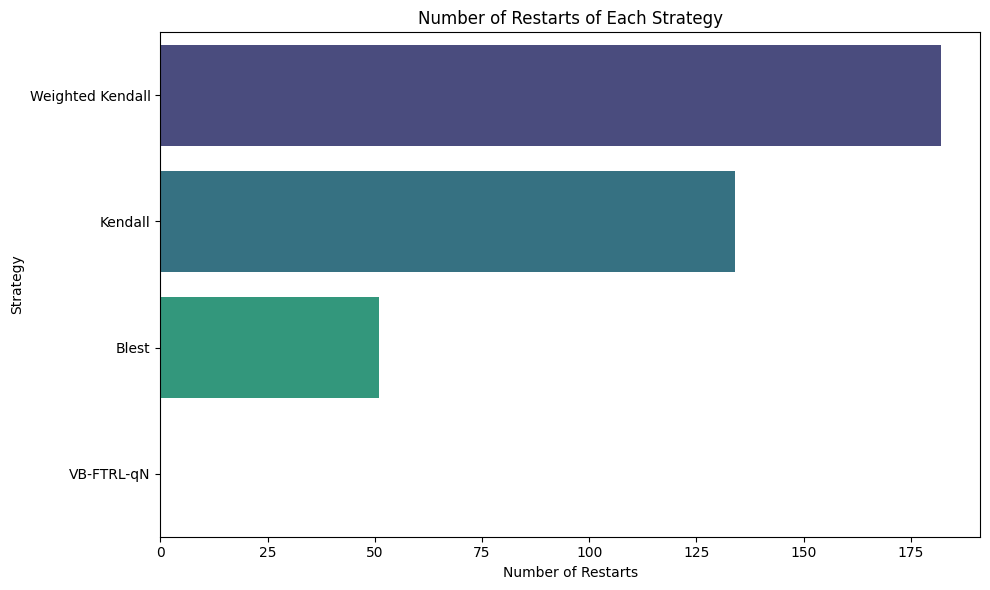

In [15]:
# We do a bar plot of the number of restarts of each strategy
n_restarts = {
    'VB-FTRL-qN': algo_no_restart.n_restart(),
    'Kendall': algo_restart_kendall.n_restart(),
    'Weighted Kendall': algo_restart_weighted_kendall.n_restart(),
    'Blest': algo_restart_blest.n_restart(),
}
n_restarts_df = pd.DataFrame(list(n_restarts.items()), columns=['Strategy', 'Number of Restarts'])
n_restarts_df = n_restarts_df.sort_values(by='Number of Restarts', ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='Number of Restarts', y='Strategy', data=n_restarts_df, palette='viridis')
ax.set_title("Number of Restarts of Each Strategy")
plt.tight_layout()
plt.show()

# Optimization of Parameters of the model.

The objective is to maximize the final capital of each algorithm wrt to the given parameters of the model. In this case we have 2 regularization terms $\mu$ and $\lambda$.
And We also have the threshold parameter for the restart functionality.

In order to find the optimal values of this parameters, we apply a genetic algorithm.

In [16]:
# Firstly we divide our data into two parts: training and testing
# We will use the first 75% of the data for training and the last 20% for testing

idx = np.floor(0.75 * len(prix_weekly))
training_data = prix_weekly.iloc[:int(idx)]
training_returns = returns_weekly.iloc[:int(idx)]
training_rescaled = rescaled_weekly.iloc[:int(idx)]

# The last 25% of the data will be used for testing
testing_data = prix_weekly.iloc[int(idx):]
testing_returns = returns_weekly.iloc[int(idx):]
testing_rescaled = rescaled_weekly.iloc[int(idx):]

# We normalize the prices of the training data
training_data = training_data / training_data.iloc[0]

## Optimization of $\mu$ and $\lambda$

In [17]:
# 1) Datos de training
R_true = training_returns.values      # (T, d)
R_rescaled = training_rescaled.values
d      = n_assets
T      = R_true.shape[0]

In [ ]:
lambda_vals = np.linspace(0.01, 1.0, 10)
mu_vals = np.linspace(0.01, 1.0, 10)
results = np.zeros((len(lambda_vals), len(mu_vals)))

for i, mu in enumerate(mu_vals):
    for j, lambda_val in enumerate(lambda_vals):
        algo = VB_FTRL(d, mu=mu, lambda_val=lambda_val, S=15,threshold = -1.0, scoring_func=scoring.mean_return)
        capital = 1.0
        w = algo.w.copy()
        for t in range(T - 1):
            capital *= np.dot(w, R_true[t] + 1)
            algo.update(R_true[t])
            w = algo.w
            w[w < 0] = 0.01
            w /= np.linalg.norm(w, 1)
        results[i,j] = capital
        print (f"mu: {mu}, lambda: {lambda_val}, capital: {capital}")

[Parallel(n_jobs=-1)]: Using backend MultiprocessingBackend with 8 concurrent workers.


KeyboardInterrupt: 

In [ ]:
#optimal results: mu: 0.01, lambda: 0.12, capital: 23.624855772960526

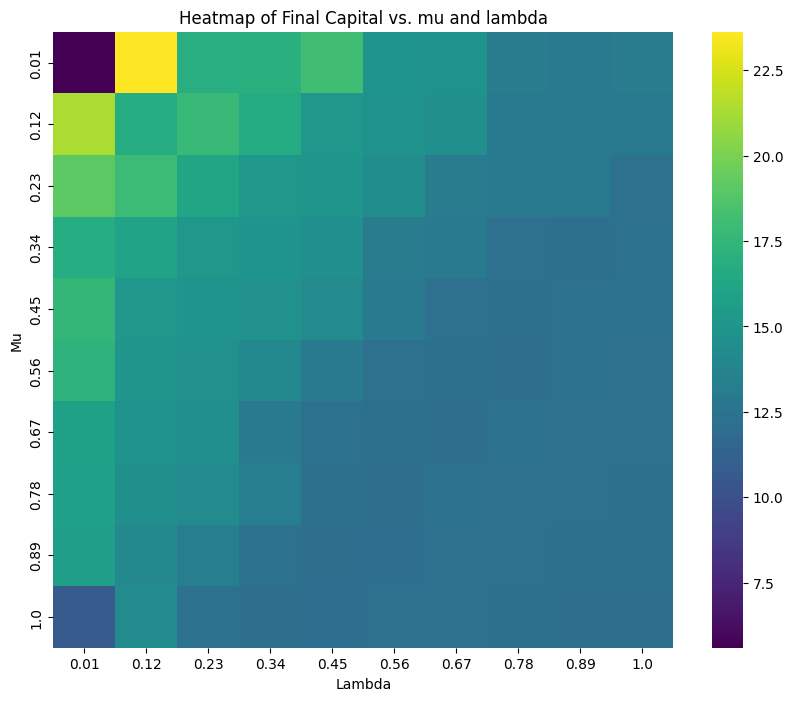

In [15]:
### Then we plot the heatmap
plt.figure(figsize=(10, 8))
### We round the values of lambda and mu to 2 decimal places for better visualization
lambda_values = np.round(lambda_vals, 3)
mu_values = np.round(mu_vals, 3)

sns.heatmap(results, xticklabels=lambda_values, yticklabels=mu_values, cmap='viridis')
plt.title('Heatmap of Final Capital vs. mu and lambda')
plt.xlabel('Lambda')
plt.ylabel('Mu')

plt.show()

In [ ]:
# Ocupar una zona para ajustar el mejor valor, por ejemplo tomar la mediana, etc.
# Here we take the center of mass of the heatmap, consideraing the mass to be the weight given by the softmax of the results
# We get the matrix of ponder weights with softmax i,j but we normalize them to start from the minimum value of the results
# ponder_weights = results - np.min(results)* np.ones(results.shape)
# we first import softmax from scipy
from scipy.special import softmax

ponder_weights = results - np.min(results) * np.ones(results.shape)
ponder_weights = softmax(ponder_weights.flatten())
ponder_weights = ponder_weights.reshape(results.shape)
# We get the center of mass of the heatmap
mu_opt = np.sum(mu_vals * ponder_weights.sum(axis=1))
lamnbda_opt = np.sum(lambda_vals * ponder_weights.sum(axis=0))
print(f"Optimal mu: {mu_opt}, Optimal lambda: {lamnbda_opt}")



AxisError: axis 1 is out of bounds for array of dimension 1

In [67]:
# We get the max capital obtained, and the corresponding lambda and mu
#max_capital = np.max(results)
#max_capital_idx = np.unravel_index(np.argmax(results, axis=None), results.shape)
#print(f"max_capital_idx: {max_capital_idx[1]}")
#max_lambda = lambda_vals[max_capital_idx[1]]
#max_mu = mu_vals[max_capital_idx[0]]
#print(f"Max capital: {max_capital}")
#print(f"Max lambda: {max_lambda}")
#print(f"Max mu: {max_mu}")
max_mu = mu_opt
max_lambda = lamnbda_opt

## Optimization of the threshold value for each strategy

### Kendall

In [17]:
threshold_vals = np.linspace(-1.0, 1.0, 50) 

In [90]:
results = np.zeros(len(threshold_vals))
num_restarts = np.zeros(len(threshold_vals))
for i, threshold in enumerate(threshold_vals):
    algo = VB_FTRL(d, mu=max_mu, lambda_val=max_lambda, S=15,threshold = threshold, scoring_func=scoring.historic_returns)
    capital = 1.0
    w = algo.w.copy()
    for t in range(T - 1):
        capital *= np.dot(w, R_true[t] + 1)
        algo.update(R_rescaled[t])
        w = algo.w
        w[w < 0] = 0.01
        w /= np.linalg.norm(w, 1)
    results[i] = capital
    num_restarts[i] = algo.n_restart()

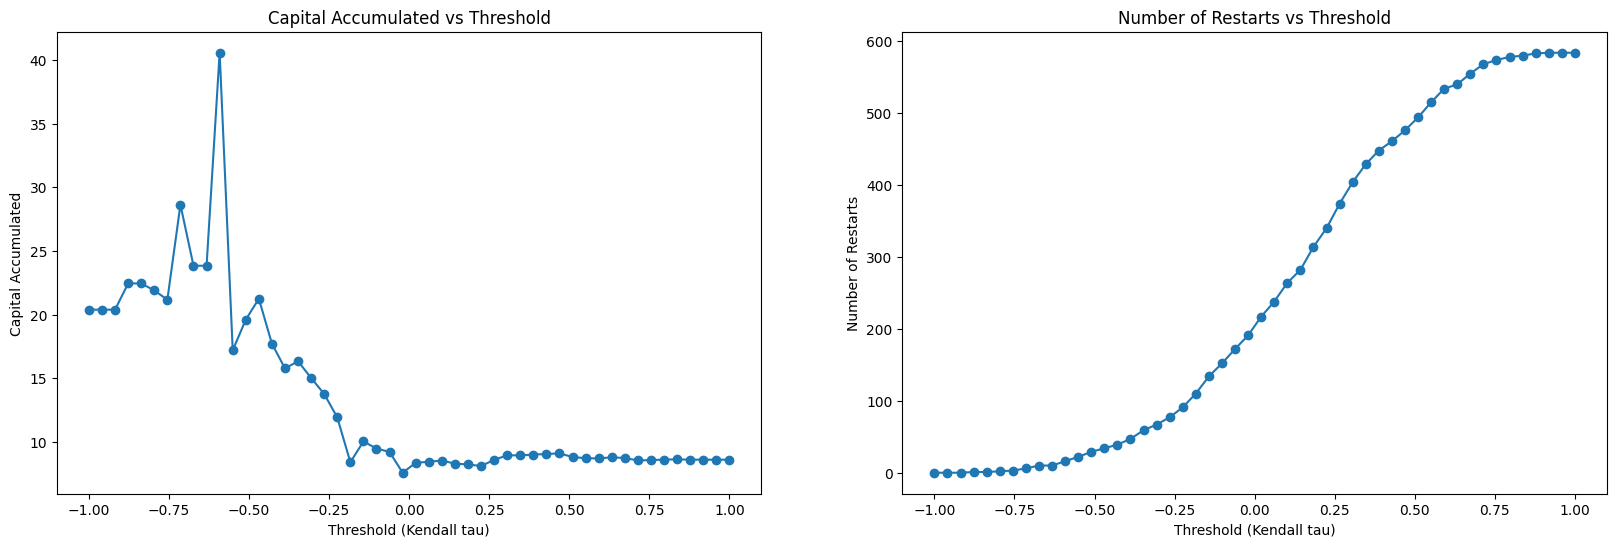

In [91]:
### Then we plot the line of capital accumulated with respect to the tolerance
fig, ax = plt.subplots(1, 2, figsize=(20,6 ))

ax[0].plot(threshold_vals, results, marker='o')
ax[0].set_title('Capital Accumulated vs Threshold')
ax[0].set_xlabel('Threshold (Kendall tau)')
ax[0].set_ylabel('Capital Accumulated')

ax[1].plot(threshold_vals, num_restarts, marker = 'o')
ax[1].set_title('Number of Restarts vs Threshold')
ax[1].set_xlabel('Threshold (Kendall tau)')
ax[1].set_ylabel('Number of Restarts')

plt.show()

## Weighted Kendall

In [ ]:
threshold_vals = np.linspace(-1.0, 1.0, 80)
results = np.zeros(len(threshold_vals))
num_restarts = np.zeros(len(threshold_vals))
for i, threshold in enumerate(threshold_vals):
    algo = VB_FTRL(d, mu=max_mu, lambda_val=max_lambda, S=15,threshold = threshold, corr_func=weightedtau, scoring_func=scoring.historic_returns)
    capital = 1.0
    w = algo.w.copy()
    for t in range(T - 1):
        capital *= np.dot(w, R_true[t] + 1)
        algo.update(R_rescaled[t])
        w = algo.w
        w[w < 0] = 0.01
        w /= np.linalg.norm(w, 1)
    results[i] = capital
    num_restarts[i] = algo.n_restart()

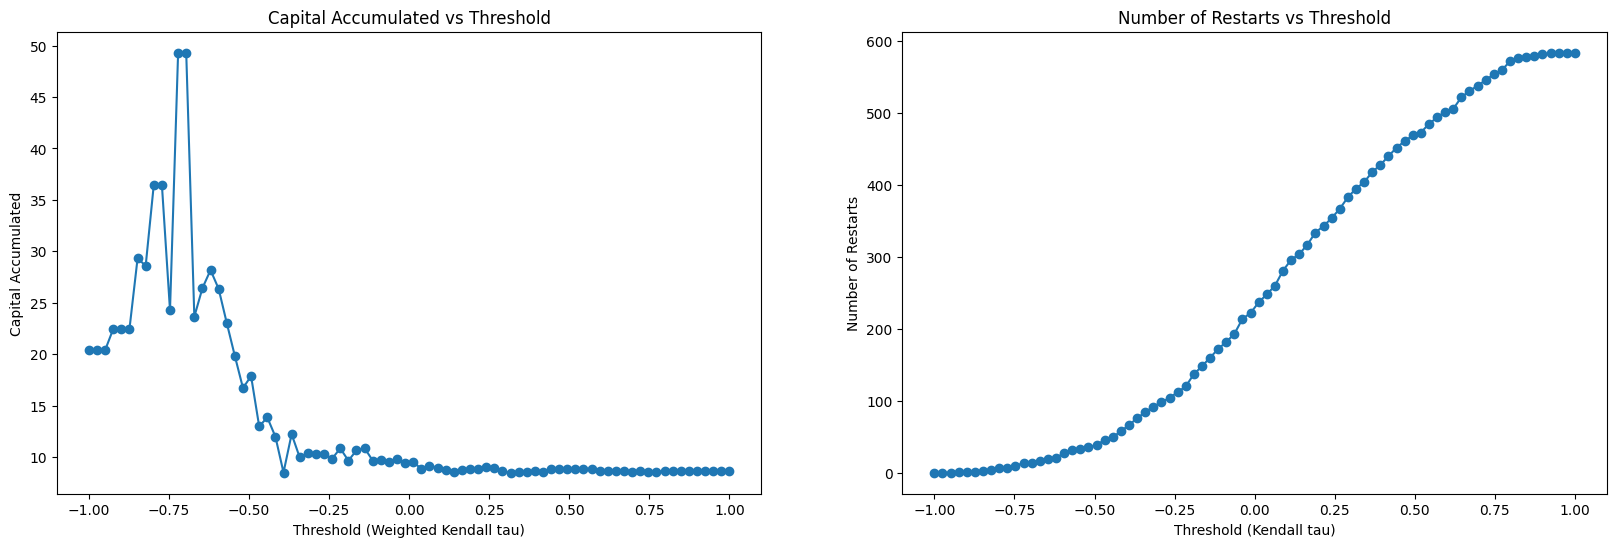

In [ ]:
### Then we plot the line of capital accumulated with respect to the tolerance
fig, ax = plt.subplots(1, 2, figsize=(20,6 ))

ax[0].plot(threshold_vals, results, marker='o')
ax[0].set_title('Capital Accumulated vs Threshold')
ax[0].set_xlabel('Threshold (Weighted Kendall tau)')
ax[0].set_ylabel('Capital Accumulated')

ax[1].plot(threshold_vals, num_restarts, marker = 'o')
ax[1].set_title('Number of Restarts vs Threshold')
ax[1].set_xlabel('Threshold (Weighted Kendall tau)')
ax[1].set_ylabel('Number of Restarts')

plt.show()

In [ ]:
# Realizamos un acercamiento a la vecindad del máximo.

In [106]:
threshold_vals = np.linspace(-0.75, -0.69, 40)
results = np.zeros(len(threshold_vals))
num_restarts = np.zeros(len(threshold_vals))
for i, threshold in enumerate(threshold_vals):
    algo = VB_FTRL(d, mu=max_mu, lambda_val=max_lambda, S=15,threshold = threshold, corr_func=weightedtau, scoring_func=scoring.historic_returns)
    capital = 1.0
    w = algo.w.copy()
    for t in range(T - 1):
        capital *= np.dot(w, R_true[t] + 1)
        algo.update(R_rescaled[t])
        w = algo.w
        w[w < 0] = 0.01
        w /= np.linalg.norm(w, 1)
    results[i] = capital
    num_restarts[i] = algo.n_restart()

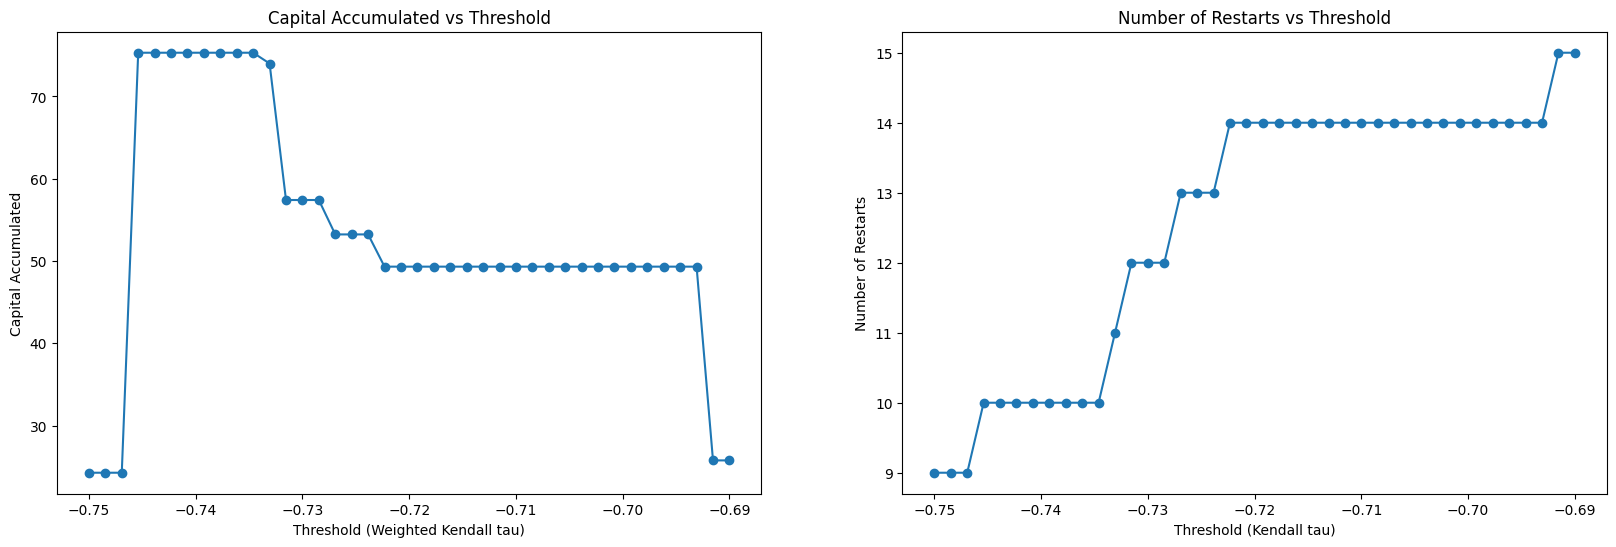

In [ ]:
### Then we plot the line of capital accumulated with respect to the tolerance
fig, ax = plt.subplots(1, 2, figsize=(20,6 ))

ax[0].plot(threshold_vals, results, marker='o')
ax[0].set_title('Capital Accumulated vs Threshold')
ax[0].set_xlabel('Threshold (Weighted Kendall tau)')
ax[0].set_ylabel('Capital Accumulated')

ax[1].plot(threshold_vals, num_restarts, marker = 'o')
ax[1].set_title('Number of Restarts vs Threshold')
ax[1].set_xlabel('Threshold (Weighted Kendall tau)')
ax[1].set_ylabel('Number of Restarts')

plt.show()

## Blest

In [108]:
threshold_vals = np.linspace(-1.0, 1.0, 50)
results = np.zeros(len(threshold_vals))
num_restarts = np.zeros(len(threshold_vals))
for i, threshold in enumerate(threshold_vals):
    algo = VB_FTRL(d, mu=max_mu, lambda_val=max_lambda, S=15,threshold = threshold, corr_func=blest_coeff,scoring_func=scoring.historic_returns)
    capital = 1.0
    w = algo.w.copy()
    for t in range(T - 1):
        capital *= np.dot(w, R_true[t] + 1)
        algo.update(R_rescaled[t])
        w = algo.w
        w[w < 0] = 0.01
        w /= np.linalg.norm(w, 1)
    results[i] = capital
    num_restarts[i] = algo.n_restart()

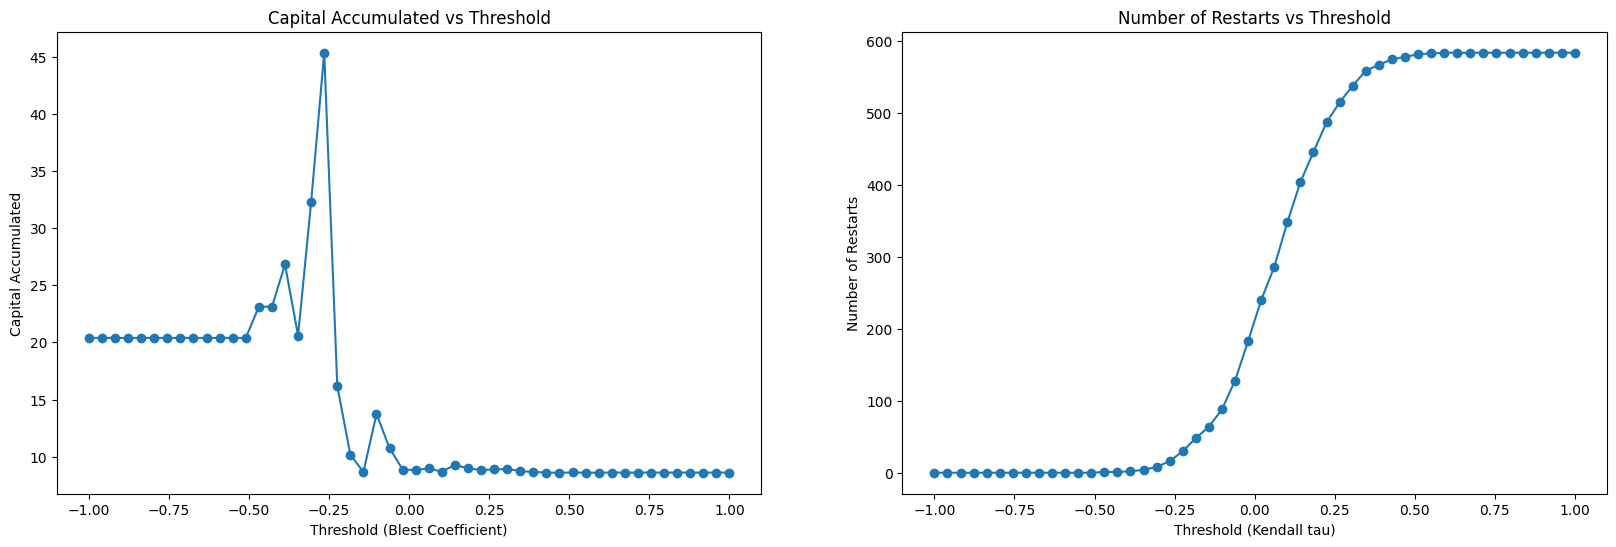

In [109]:
### Then we plot the line of capital accumulated with respect to the tolerance
fig, ax = plt.subplots(1, 2, figsize=(20,6 ))

ax[0].plot(threshold_vals, results, marker='o')
ax[0].set_title('Capital Accumulated vs Threshold')
ax[0].set_xlabel('Threshold (Blest Coefficient)')
ax[0].set_ylabel('Capital Accumulated')

ax[1].plot(threshold_vals, num_restarts, marker = 'o')
ax[1].set_title('Number of Restarts vs Threshold')
ax[1].set_xlabel('Threshold (Kendall tau)')
ax[1].set_ylabel('Number of Restarts')

plt.show()

In [ ]:
# 1) Datos de training
R_true = training_returns.values      # (T, d)
d      = n_assets
T      = R_true.shape[0]

algo = VB_FTRL(d, mu=0.01, lambda_val=0.12, S=15,threshold = -0.3005859375, corr_func=blest_coeff, scoring_func=scoring.historic_returns)
capital = 1.0
w = algo.w.copy()
for t in range(T - 1):
    x = training_rescaled.iloc[t].values
    capital *= np.dot(w, x + 1)
    algo.update(R_true[t])
    w = algo.w
    w[w < 0] = 0.01
    w /= np.linalg.norm(w, 1)

print(capital)
print(algo.n_restart())

52.31894773176616
10


In [ ]:
# -0.1, 11.67, 89
# -0.2, 13.89, 39

# -0.25, 15.94, 21

# -0.275, 39.87, 14

# -0.2875, 40.006, 12

# -0.29375, 40.006, 12

# -0.296875, 40.006, 12
# -0.2984375, 51.46, 11
# -0.3, 51.46, 11
# -0.300390625, 51.46, 11
# -0.3005859375, 52.31, 10
# -0.30078125, 52.77, 9 # OPTIMAL VALUE
# -0.3015625, 32.69, 8
# -0.303125, 32.69, 8

# -0.30625, 32.69, 8

# -0.3125, 24.25, 5

# -0.325, 20.75, 4

# -0.35, 20.75, 4

# -0.4, 26.85, 2
# -0.5, 23.26, 1
# -0.6, 20.53, 0

In [112]:
threshold_vals = np.linspace(-0.3, -0.301, 20)
results = np.zeros(len(threshold_vals))
num_restarts = np.zeros(len(threshold_vals))
for i, threshold in enumerate(threshold_vals):
    algo = VB_FTRL(d, mu=max_mu, lambda_val=max_lambda, S=15,threshold = threshold, corr_func=blest_coeff,scoring_func=scoring.historic_returns)
    capital = 1.0
    w = algo.w.copy()
    for t in range(T - 1):
        capital *= np.dot(w, R_true[t] + 1)
        algo.update(R_rescaled[t])
        w = algo.w
        w[w < 0] = 0.01
        w /= np.linalg.norm(w, 1)
    results[i] = capital
    num_restarts[i] = algo.n_restart()

Text(0, 0.5, 'Number of Restarts')

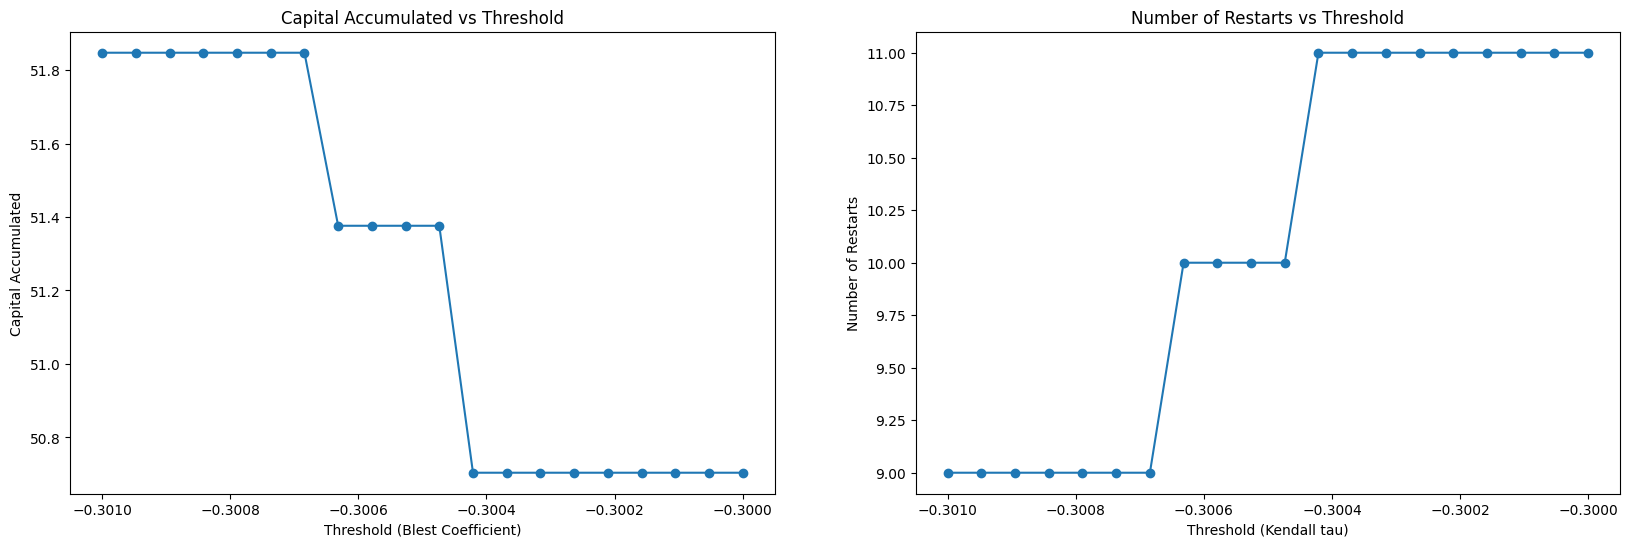

In [113]:
### Then we plot the line of capital accumulated with respect to the tolerance
fig, ax = plt.subplots(1, 2, figsize=(20,6 ))

ax[0].plot(threshold_vals, results, marker='o')
ax[0].set_title('Capital Accumulated vs Threshold')
ax[0].set_xlabel('Threshold (Blest Coefficient)')
ax[0].set_ylabel('Capital Accumulated')

ax[1].plot(threshold_vals, num_restarts, marker = 'o')
ax[1].set_title('Number of Restarts vs Threshold')
ax[1].set_xlabel('Threshold (Kendall tau)')
ax[1].set_ylabel('Number of Restarts')

## Testing

In [18]:
n_assets = testing_returns.shape[1]
Tw = testing_data.shape[0]
R = testing_returns.values      # (T, d)
R_rescaled = testing_rescaled.values
d = n_assets
T = R.shape[0]


# 2) Initialize capital arrays
capital_classic = np.zeros(Tw); capital_classic[0] = 1.0
capital_opti    = np.zeros(Tw); capital_opti[0]    = 1.0
capital_uniform    = np.zeros(Tw); capital_uniform[0]    = 1.0

# 3) Instantiate algorithms
algo_classic = VB_FTRL(n_assets, mu=0.2, lambda_val=0.2, threshold=-1.0, scoring_func=scoring.historic_returns)  # threshold < -1 so never restarts
algo_opti   = VB_FTRL(n_assets, mu=0.01, lambda_val=0.12, threshold= -1.0, scoring_func=scoring.historic_returns)   # restart when tau < 0

# 4) Keep track of weights for plotting
pastw_classic = [algo_classic.w.copy()]
pastw_opti = [algo_opti.w.copy()]

# 5) Weekly backtest loop
for t in range(T):
    # actual return vector
    r = R[t]
    r_rescaled = R_rescaled[t]
    # Uniform strategy
    capital_uniform[t+1] = capital_uniform[t] * (np.sum(r + 1) / n_assets)

    # Classic algorithm
    w_classic = algo_classic.w.copy()
    capital_classic[t+1] = capital_classic[t] * np.dot(w_classic, r + 1)
    # update on the raw features (rescaled returns)
    algo_classic.update(r_rescaled)
    # enforce positivity and simplex
    algo_classic.w[algo_classic.w < 0] = 0.1
    algo_classic.w /= np.linalg.norm(algo_classic.w, 1)
    pastw_classic.append(algo_classic.w.copy())

    # Optimized algorithm
    w_opti= algo_opti.w.copy()
    capital_opti[t+1] = capital_opti[t] * np.dot(w_opti, r + 1)
    algo_opti.update(r_rescaled)
    algo_opti.w[algo_opti.w < 0] = 0.1
    algo_opti.w /= np.linalg.norm(algo_opti.w, 1)
    pastw_opti.append(algo_opti.w.copy())

In [19]:
testing_data = testing_data / testing_data.iloc[0]

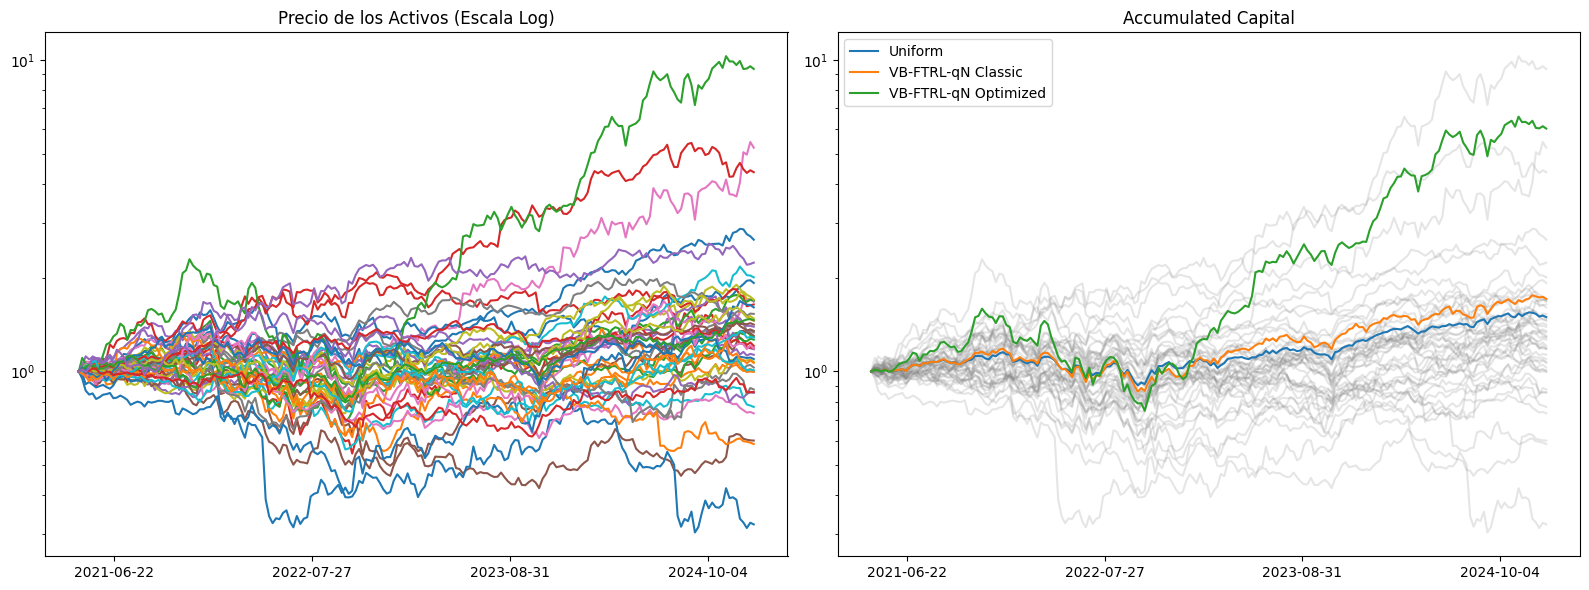

In [20]:
# 6) Plotting
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Asset prices (log scale)
axes[0].plot(testing_data.index, testing_data.values)
axes[0].set_title("Precio de los Activos (Escala Log)")
axes[0].set_yscale('log')
axes[0].xaxis.set_major_locator(MaxNLocator(nbins=5))

# Cumulative capital
axes[1].plot(testing_data.index, testing_data.values, color='gray', alpha=0.2)
axes[1].plot(testing_data.index, capital_uniform, label='Uniform')
axes[1].plot(testing_data.index, capital_classic, label='VB-FTRL-qN Classic')
axes[1].plot(testing_data.index, capital_opti, label='VB-FTRL-qN Optimized')
axes[1].set_title("Accumulated Capital")
axes[1].set_yscale('log')
axes[1].legend()
axes[1].xaxis.set_major_locator(MaxNLocator(nbins=5))


plt.tight_layout()
plt.show()

C:\Users\Javier Toro B\AppData\Local\Temp\ipykernel_8296\1884052849.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Final Capital', y='Strategy', data=final_capital_df, palette='viridis')


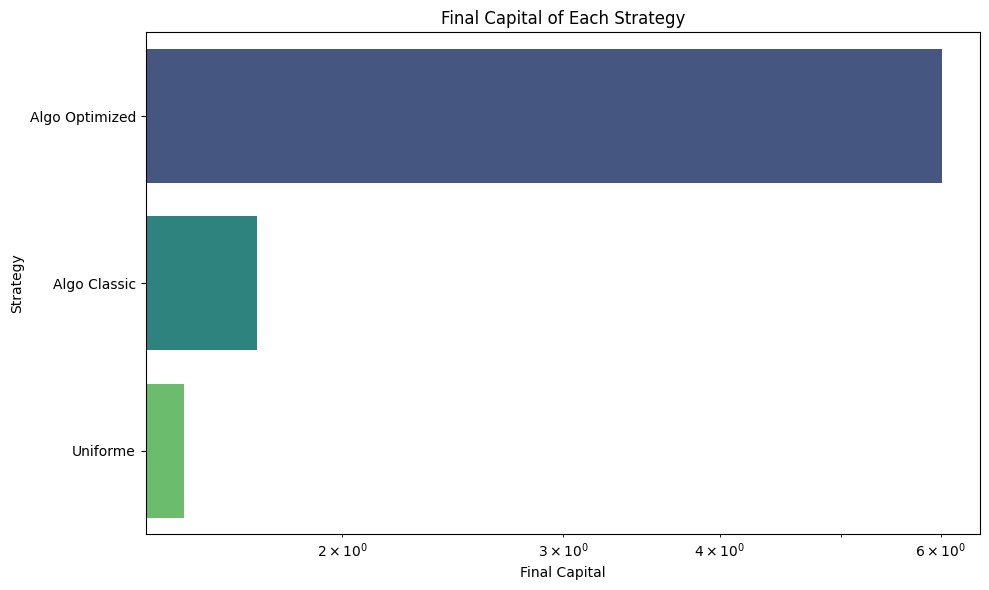

In [21]:
# We do a bar plot of the final capital of each strategy
final_capital = {
    'Algo Classic': capital_classic[-1],
    'Algo Optimized': capital_opti[-1],
    'Uniforme': capital_uniform[-1]
}
final_capital_df = pd.DataFrame(list(final_capital.items()), columns=['Strategy', 'Final Capital'])
final_capital_df = final_capital_df.sort_values(by='Final Capital', ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='Final Capital', y='Strategy', data=final_capital_df, palette='viridis')
ax.set_title("Final Capital of Each Strategy")
ax.set_xscale('log')
plt.tight_layout()
plt.show()

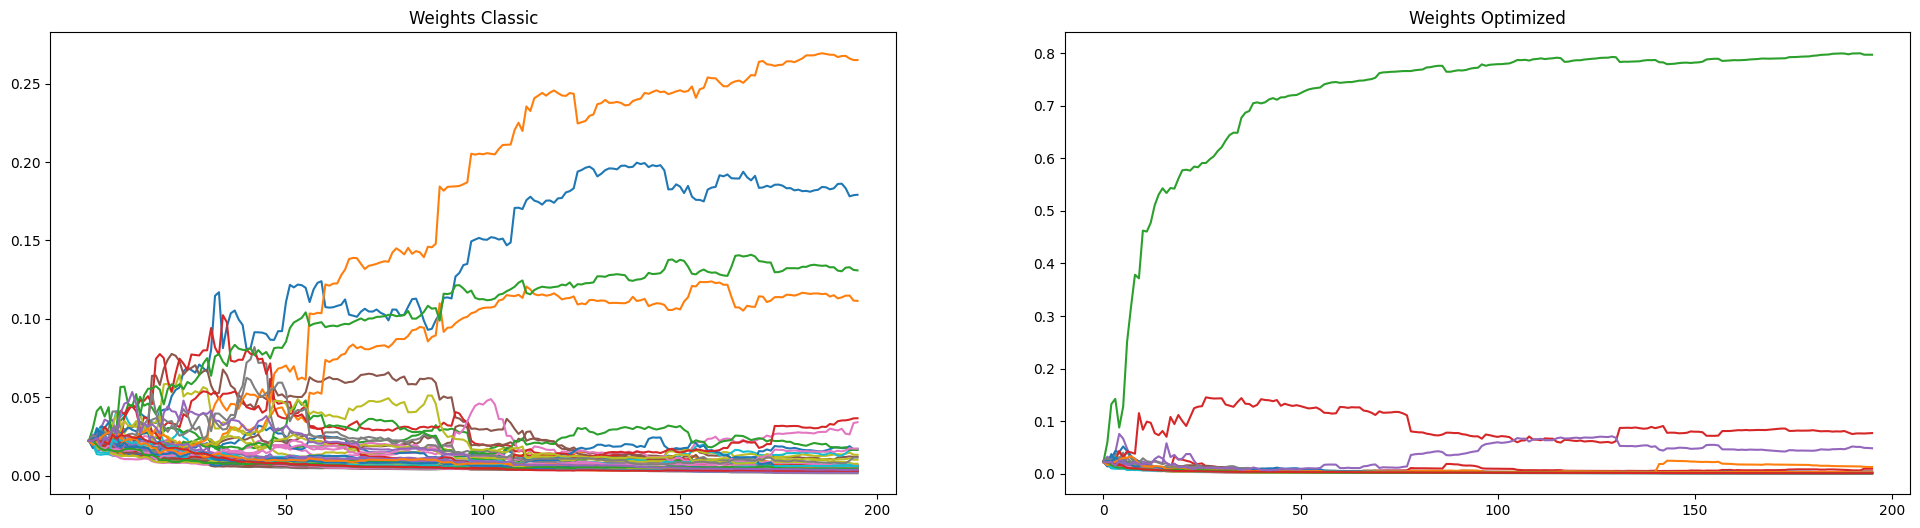

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(24,6))
# Weights Kendall 
axes[0].plot(pd.Index(range(len(pastw_classic))), np.array(pastw_classic))
axes[0].set_title("Weights Classic")
axes[0].xaxis.set_major_locator(MaxNLocator(nbins=5))

# Weights weighted Kendall
axes[1].plot(pd.Index(range(len(pastw_opti))), np.array(pastw_opti))
axes[1].set_title("Weights Optimized")
axes[1].xaxis.set_major_locator(MaxNLocator(nbins=5))

### Optimized Restart Strategies

### Kendall Restart

In [23]:
# 2) Initialize capital arrays
capital_classic   = np.zeros(Tw); capital_classic[0]   = 1.0
capital_opti      = np.zeros(Tw); capital_opti[0]      = 1.0
capital_uniform   = np.zeros(Tw); capital_uniform[0]   = 1.0
capital_restart1y = np.zeros(Tw); capital_restart1y[0] = 1.0  # curva anual

# 3) Instantiate algorithms
algo_classic   = VB_FTRL(n_assets, mu=0.2,  lambda_val=0.2,  threshold=-0.2, scoring_func=scoring.historic_returns)
algo_opti      = VB_FTRL(n_assets, mu=0.01, lambda_val=0.12, threshold=-0.6, scoring_func=scoring.historic_returns)
algo_restart1y = VB_FTRL(n_assets, mu=0.2,  lambda_val=0.2,  threshold=-1.0, scoring_func=scoring.historic_returns)  # reinicios manuales

# 4) Keep track of weights for plotting
pastw_classic   = [algo_classic.w.copy()]
pastw_opti      = [algo_opti.w.copy()]
pastw_restart1y = [algo_restart1y.w.copy()]

# 5) Weekly backtest loop
semanas_por_1y = 52  # ≈ 1 año en semanas

for t in range(T):
    # actual return vector
    r = R[t]
    r_rescaled = R_rescaled[t]

    # Uniform strategy
    capital_uniform[t + 1] = capital_uniform[t] * (np.sum(r + 1) / n_assets)

    # Classic algorithm
    w_classic = algo_classic.w.copy()
    capital_classic[t + 1] = capital_classic[t] * np.dot(w_classic, (r + 1))
    algo_classic.update(r_rescaled)
    algo_classic.w[algo_classic.w < 0] = 0.1
    algo_classic.w /= np.linalg.norm(algo_classic.w, 1)
    pastw_classic.append(algo_classic.w.copy())

    # Optimized algorithm
    w_opti = algo_opti.w.copy()
    capital_opti[t + 1] = capital_opti[t] * np.dot(w_opti, (r + 1))
    algo_opti.update(r_rescaled)
    algo_opti.w[algo_opti.w < 0] = 0.1
    algo_opti.w /= np.linalg.norm(algo_opti.w, 1)
    pastw_opti.append(algo_opti.w.copy())

    # --- Algoritmo que reinicia cada 1 año (52 semanas) ---
    if (t > 0) and (t % semanas_por_1y == 0):
        prev_index = t - 1
        prev_return = R[prev_index]
        algo_restart1y.restart(prev_return, prev_index)
        # Sobrescribir el peso en la iteración t con el peso recién reiniciado
        pastw_restart1y[t] = algo_restart1y.w.copy()

    # Calcular capital para restart1y usando el peso actual
    w_r1 = algo_restart1y.w.copy()
    capital_restart1y[t + 1] = capital_restart1y[t] * np.dot(w_r1, (r + 1))

    # Actualizar algoritmo restart1y para la próxima semana
    algo_restart1y.update(r_rescaled)
    algo_restart1y.w[algo_restart1y.w < 0] = 0.1
    algo_restart1y.w /= np.linalg.norm(algo_restart1y.w, 1)
    pastw_restart1y.append(algo_restart1y.w.copy())



C:\Users\Javier Toro B\AppData\Local\Temp\ipykernel_8296\3379141718.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0].legend(loc='upper left', fontsize='small')


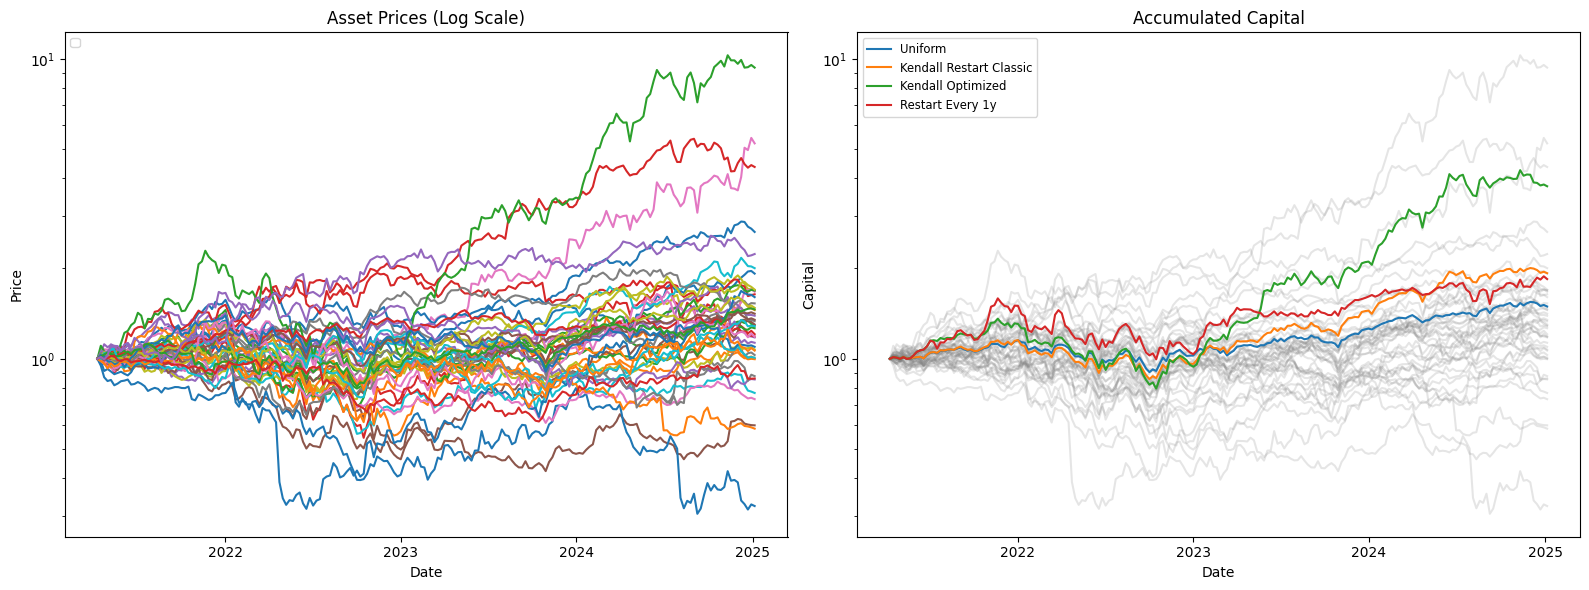

In [39]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import MaxNLocator

# 6) Plotting
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True)

# — Left subplot: Asset prices (log scale) per ticker
for ticker in testing_data.columns:
    axes[0].plot(testing_data.index, testing_data[ticker])
axes[0].set_title("Asset Prices (Log Scale)")
axes[0].set_yscale('log')
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Price")
axes[0].xaxis.set_major_locator(mdates.YearLocator())
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.setp(axes[0].get_xticklabels(), rotation=0, ha='center')
axes[0].legend(loc='upper left', fontsize='small')

# — Right subplot: Cumulative capital with gray background lines intact
# Plot gray background lines for asset prices
axes[1].plot(testing_data.index, testing_data.values, color='gray', alpha=0.2)

# Plot the capital trajectories on top
axes[1].plot(testing_data.index, capital_uniform, label='Uniform')
axes[1].plot(testing_data.index, capital_classic, label='Kendall Restart Classic')
axes[1].plot(testing_data.index, capital_opti, label='Kendall Optimized')
axes[1].plot(testing_data.index, capital_restart1y, label='Restart Every 1y')

axes[1].set_title("Accumulated Capital")
axes[1].set_yscale('log')
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Capital")
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.setp(axes[1].get_xticklabels(), rotation=0, ha='center')
axes[1].legend(loc='upper left', fontsize='small')

plt.tight_layout()
plt.show()


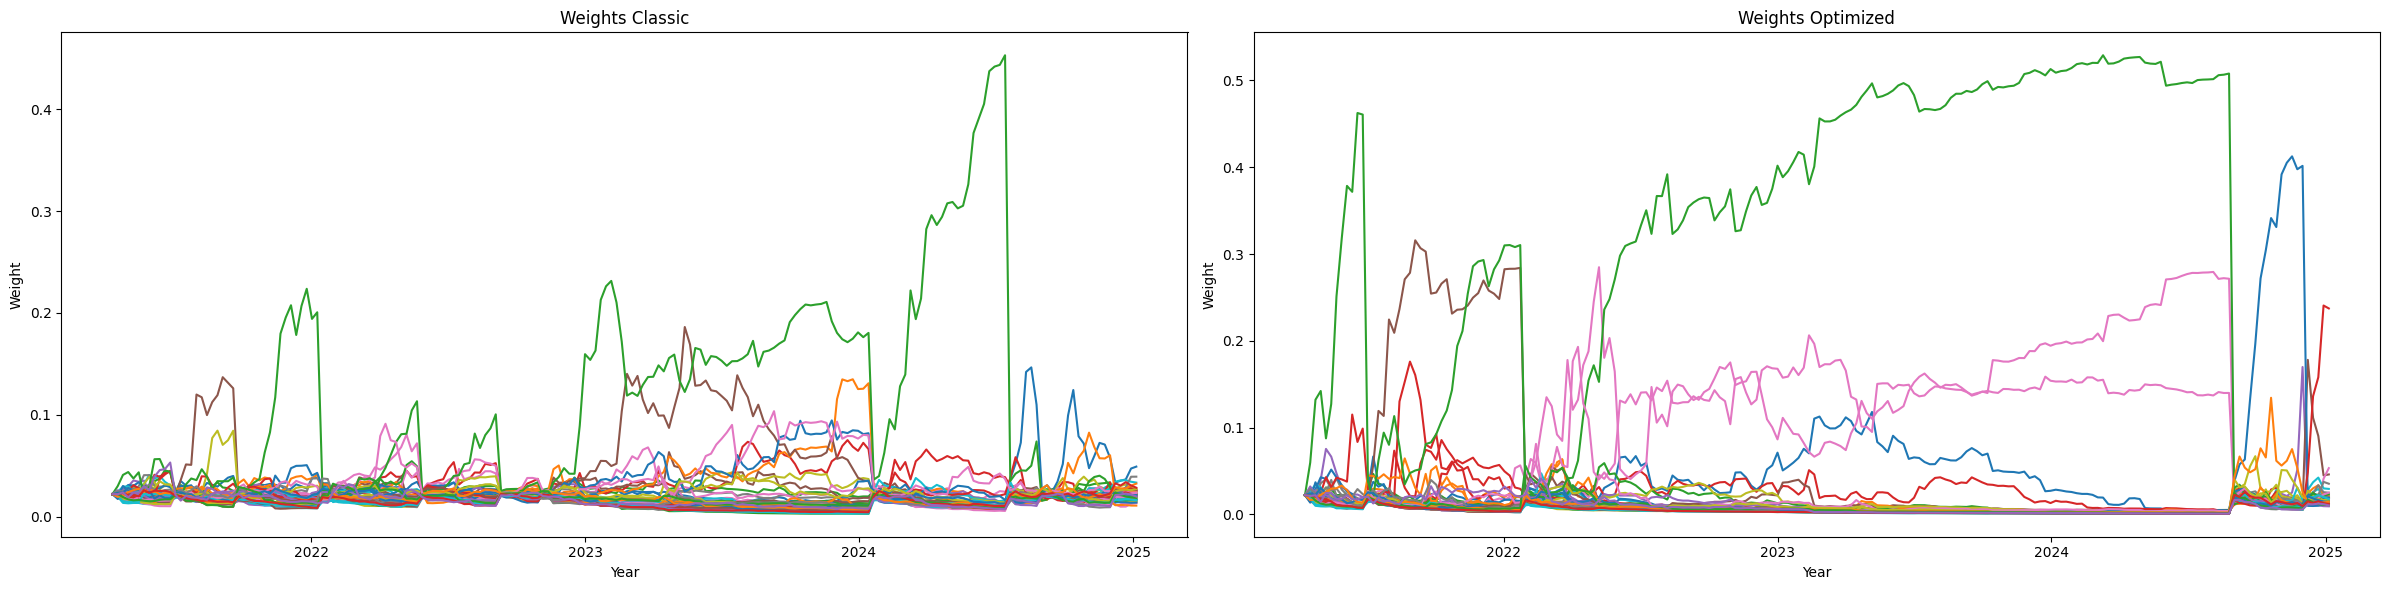

In [40]:
import matplotlib.dates as mdates

# Convert weight histories to NumPy arrays
weights_classic = np.array(pastw_classic)
weights_opti    = np.array(pastw_opti)

# Use the same weekly index from testing_data for the x-axis
dates = testing_data.index

fig, axes = plt.subplots(1, 2, figsize=(24, 6), sharex=True)

# — Left subplot: Weights Classic
axes[0].plot(dates, weights_classic)
axes[0].set_title("Weights Classic")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Weight")
axes[0].xaxis.set_major_locator(mdates.YearLocator())
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.setp(axes[0].get_xticklabels(), rotation=0, ha='center')

# — Right subplot: Weights Optimized
axes[1].plot(dates, weights_opti)
axes[1].set_title("Weights Optimized")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Weight")
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.setp(axes[1].get_xticklabels(), rotation=0, ha='center')

plt.tight_layout()
plt.show()


C:\Users\Javier Toro B\AppData\Local\Temp\ipykernel_8296\3773232995.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


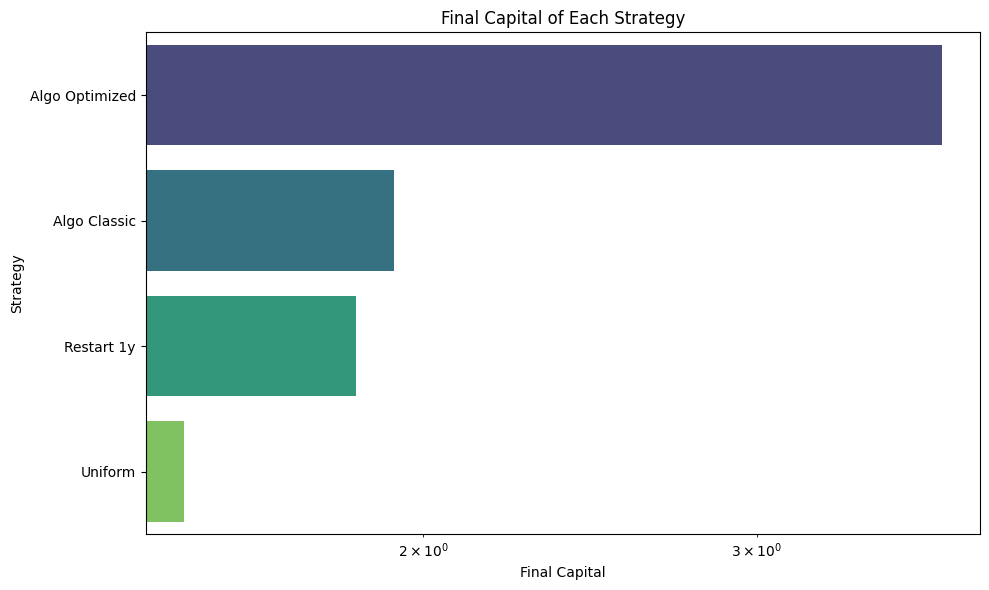

In [41]:
import seaborn as sns

# Assuming you have a capital_restart1y array defined:
# Replace capital_restart1y with the actual variable name if different.

# 1) Prepare the final capital dictionary including the 1-year restart strategy
final_capital = {
    'Algo Classic': capital_classic[-1],
    'Algo Optimized': capital_opti[-1],
    'Uniform': capital_uniform[-1],
    'Restart 1y': capital_restart1y[-1]  # nueva curva
}

# 2) Create a DataFrame and sort by final capital descending
final_capital_df = pd.DataFrame(
    list(final_capital.items()), 
    columns=['Strategy', 'Final Capital']
)
final_capital_df = final_capital_df.sort_values(by='Final Capital', ascending=False)

# 3) Plot as a horizontal barplot (log-scaled x-axis)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    x='Final Capital', 
    y='Strategy', 
    data=final_capital_df, 
    palette='viridis', 
    ax=ax
)
ax.set_title("Final Capital of Each Strategy")
ax.set_xscale('log')
plt.tight_layout()
plt.show()


C:\Users\Javier Toro B\AppData\Local\Temp\ipykernel_8296\965669874.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Number of Restarts', y='Strategy', data=n_restarts_df, palette='viridis')


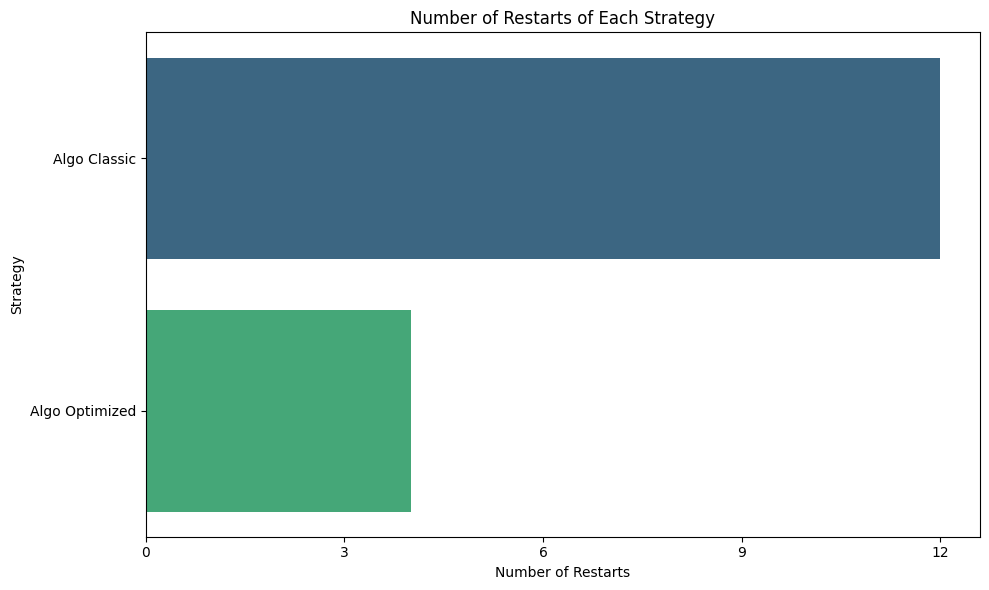

In [42]:
# Barplot of the number of restarts of each strategy
n_restarts = {
    'Algo Classic': algo_classic.n_restart(),
    'Algo Optimized': algo_opti.n_restart(),
}
n_restarts_df = pd.DataFrame(list(n_restarts.items()), columns=['Strategy', 'Number of Restarts'])
n_restarts_df = n_restarts_df.sort_values(by='Number of Restarts', ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='Number of Restarts', y='Strategy', data=n_restarts_df, palette='viridis')
ax.set_title("Number of Restarts of Each Strategy")
ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
plt.tight_layout()
plt.show()

### Weighted Kendall

In [43]:
# 2) Initialize capital arrays
capital_classic     = np.zeros(Tw); capital_classic[0]     = 1.0
capital_opti        = np.zeros(Tw); capital_opti[0]        = 1.0
capital_uniform     = np.zeros(Tw); capital_uniform[0]     = 1.0
capital_restart1y   = np.zeros(Tw); capital_restart1y[0]   = 1.0  # nueva curva: reinicio anual

# 3) Instantiate algorithms
algo_classic    = VB_FTRL(
    n_assets,
    mu=0.2,
    lambda_val=0.2,
    threshold=-0.2,
    corr_func=weightedtau,
    scoring_func=scoring.historic_returns
)
algo_opti       = VB_FTRL(
    n_assets,
    mu=0.01,
    lambda_val=0.12,
    threshold=-0.7375,
    corr_func=weightedtau,
    scoring_func=scoring.historic_returns
)
algo_restart1y  = VB_FTRL(
    n_assets,
    mu=0.2,
    lambda_val=0.2,
    threshold=-1.0,                   # sin reinicios automáticos; reiniciaremos manualmente cada 52 semanas
    corr_func=weightedtau,
    scoring_func=scoring.historic_returns
)

# 4) Keep track of weights for plotting
pastw_classic   = [algo_classic.w.copy()]
pastw_opti      = [algo_opti.w.copy()]
pastw_restart1y = [algo_restart1y.w.copy()]  # nueva lista para pesos tras reinicio anual

# 5) Weekly backtest loop
#    52 semanas ≈ 1 año
semanas_por_1y = 52

for t in range(T):
    # actual return vector
    r = R[t]
    r_rescaled = R_rescaled[t]

    # Uniform strategy
    capital_uniform[t + 1] = capital_uniform[t] * (np.sum(r + 1) / n_assets)

    # Classic algorithm
    w_classic = algo_classic.w.copy()
    capital_classic[t + 1] = capital_classic[t] * np.dot(w_classic, (r + 1))
    algo_classic.update(r_rescaled)
    algo_classic.w[algo_classic.w < 0] = 0.1
    algo_classic.w /= np.linalg.norm(algo_classic.w, 1)
    pastw_classic.append(algo_classic.w.copy())

    # Optimized algorithm
    w_opti = algo_opti.w.copy()
    capital_opti[t + 1] = capital_opti[t] * np.dot(w_opti, (r + 1))
    algo_opti.update(r_rescaled)
    algo_opti.w[algo_opti.w < 0] = 0.1
    algo_opti.w /= np.linalg.norm(algo_opti.w, 1)
    pastw_opti.append(algo_opti.w.copy())

    # --- Algoritmo que reinicia cada 1 año (52 semanas) ---
    # Reinicio manual cada 52 semanas (t > 0 para tener prev_return)
    if (t > 0) and (t % semanas_por_1y == 0):
        prev_index = t - 1
        prev_return = R[prev_index]
        algo_restart1y.restart(prev_return, prev_index)
        # Sobrescribir el peso en la iteración t con el peso recién reiniciado
        pastw_restart1y[t] = algo_restart1y.w.copy()

    # Calcular capital para restart1y usando el peso actual
    w_r1 = algo_restart1y.w.copy()
    capital_restart1y[t + 1] = capital_restart1y[t] * np.dot(w_r1, (r + 1))

    # Actualizar algoritmo restart1y para la próxima semana
    algo_restart1y.update(r_rescaled)
    algo_restart1y.w[algo_restart1y.w < 0] = 0.1
    algo_restart1y.w /= np.linalg.norm(algo_restart1y.w, 1)
    pastw_restart1y.append(algo_restart1y.w.copy())


C:\Users\Javier Toro B\AppData\Local\Temp\ipykernel_8296\33375998.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0].legend(loc='upper left', fontsize='small')


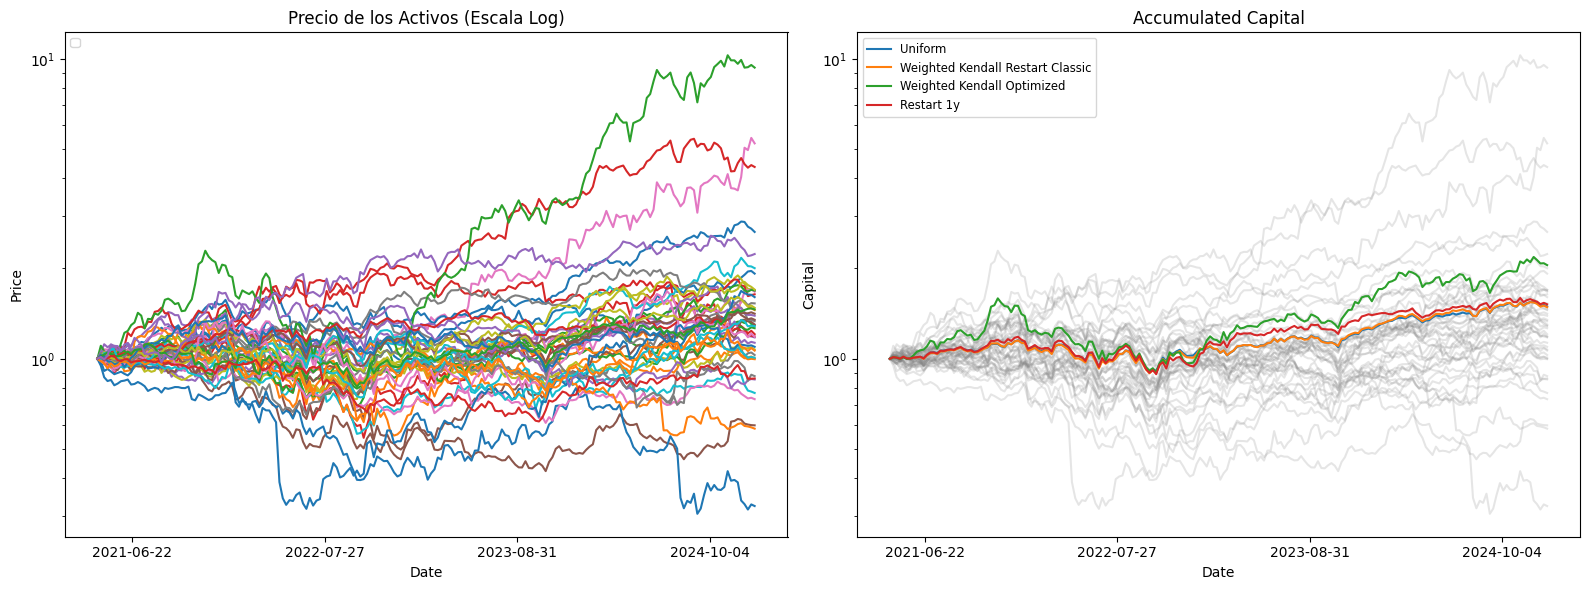

In [44]:
# 6) Plotting
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# — Left subplot: Asset prices (log scale)
for ticker in testing_data.columns:
    axes[0].plot(testing_data.index, testing_data[ticker])
axes[0].set_title("Precio de los Activos (Escala Log)")
axes[0].set_yscale('log')
axes[0].xaxis.set_major_locator(MaxNLocator(nbins=5))
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Price")
axes[0].legend(loc='upper left', fontsize='small')

# — Right subplot: Cumulative capital (with gray background lines)
# Gray background: asset prices
axes[1].plot(testing_data.index, testing_data.values, color='gray', alpha=0.2)

# Plot each strategy’s capital
axes[1].plot(testing_data.index, capital_uniform, label='Uniform')
axes[1].plot(testing_data.index, capital_classic, label='Weighted Kendall Restart Classic')
axes[1].plot(testing_data.index, capital_opti, label='Weighted Kendall Optimized')
axes[1].plot(testing_data.index, capital_restart1y, label='Restart 1y')  # curva anual agregada

axes[1].set_title("Accumulated Capital")
axes[1].set_yscale('log')
axes[1].xaxis.set_major_locator(MaxNLocator(nbins=5))
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Capital")
axes[1].legend(loc='upper left', fontsize='small')

plt.tight_layout()
plt.show()

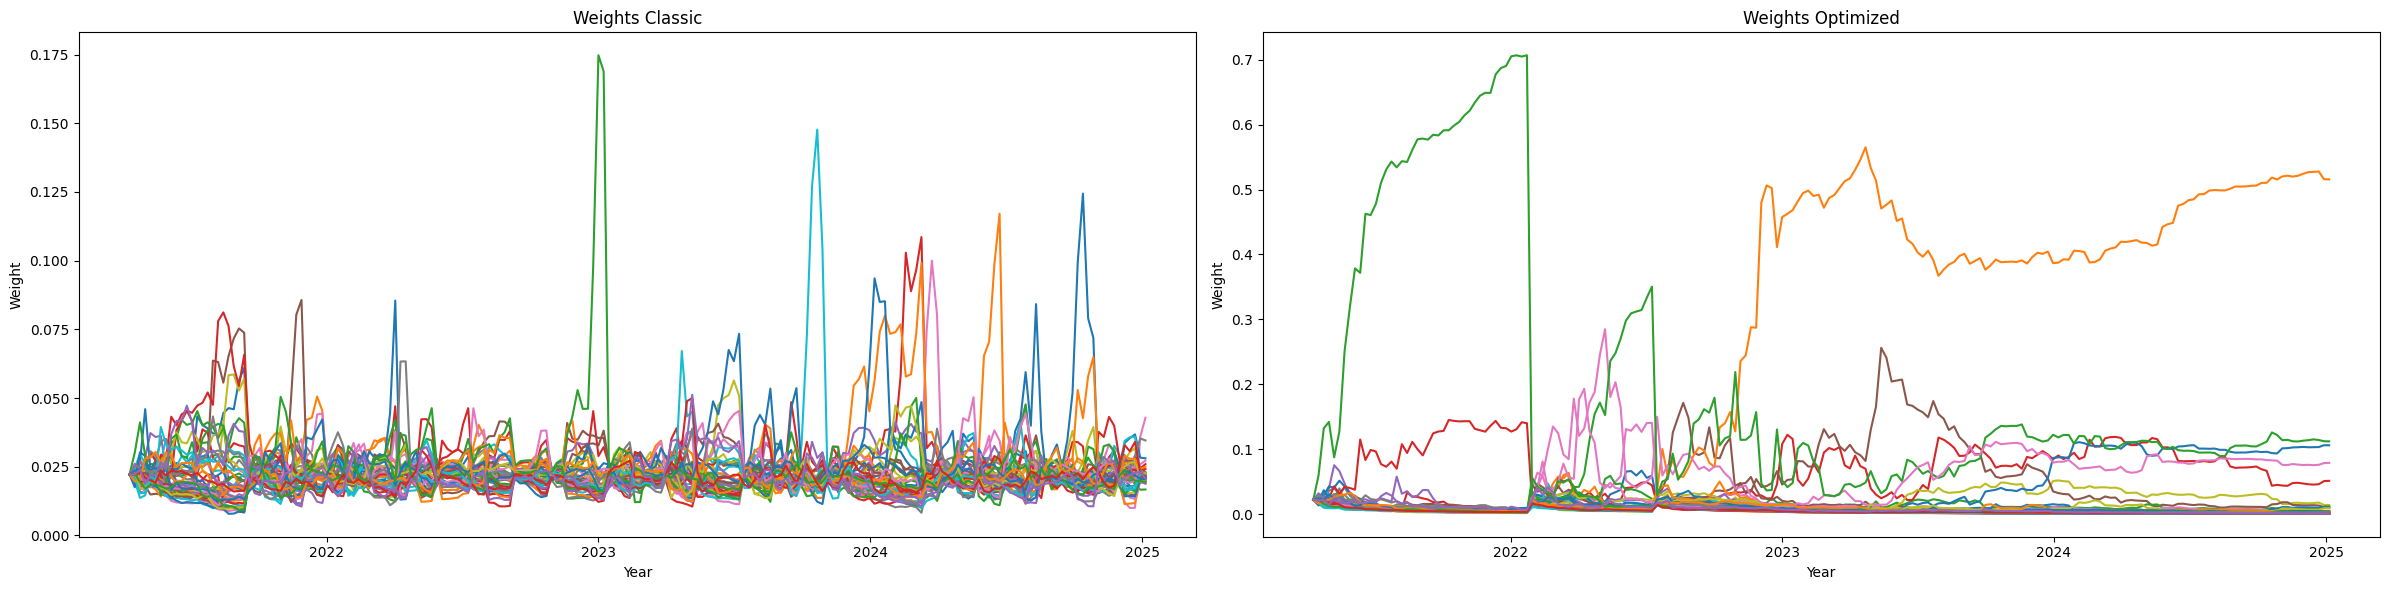

In [45]:
import matplotlib.dates as mdates

# Convert weight histories to NumPy arrays
weights_classic = np.array(pastw_classic)
weights_opti    = np.array(pastw_opti)

# Use the same weekly index from testing_data for the x-axis (ensure lengths match)
dates = testing_data.index[:len(weights_classic)]

fig, axes = plt.subplots(1, 2, figsize=(24, 6), sharex=True)

# — Left subplot: Weights Classic
axes[0].plot(dates, weights_classic)
axes[0].set_title("Weights Classic")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Weight")
axes[0].xaxis.set_major_locator(mdates.YearLocator())
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.setp(axes[0].get_xticklabels(), rotation=0, ha='center')

# — Right subplot: Weights Optimized
# Make sure to use the same dates array (it should also match len(weights_opti))
axes[1].plot(dates, weights_opti)
axes[1].set_title("Weights Optimized")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Weight")
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.setp(axes[1].get_xticklabels(), rotation=0, ha='center')

plt.tight_layout()
plt.show()


C:\Users\Javier Toro B\AppData\Local\Temp\ipykernel_8296\1144233905.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Final Capital', y='Strategy', data=final_capital_df, palette='viridis')


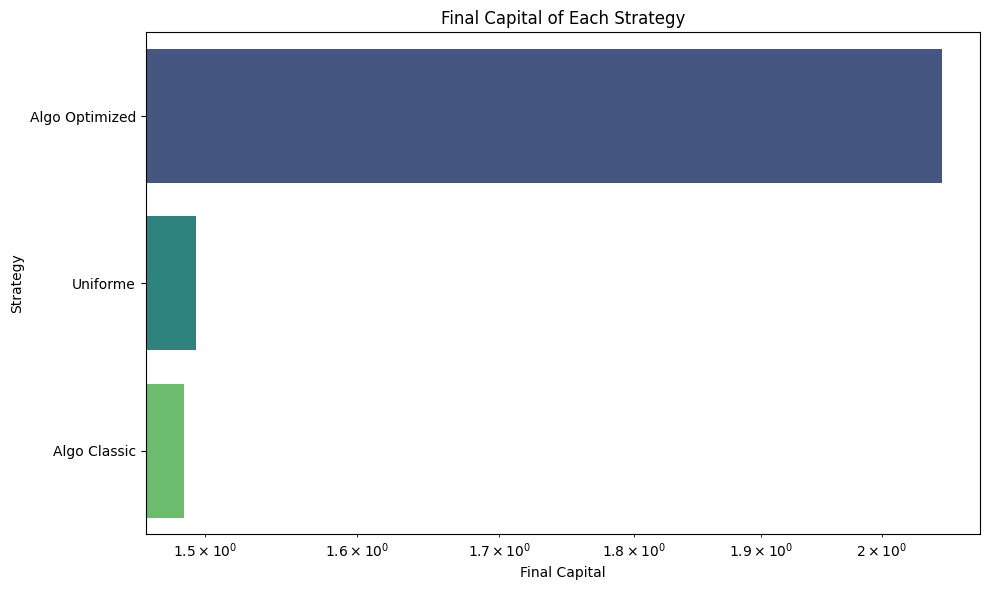

In [46]:
# barplot of the number of the final capital of each strategy
final_capital = {
    'Algo Classic': capital_classic[-1],
    'Algo Optimized': capital_opti[-1],
    'Uniforme': capital_uniform[-1]
}
final_capital_df = pd.DataFrame(list(final_capital.items()), columns=['Strategy', 'Final Capital'])
final_capital_df = final_capital_df.sort_values(by='Final Capital', ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='Final Capital', y='Strategy', data=final_capital_df, palette='viridis')
ax.set_title("Final Capital of Each Strategy")
ax.set_xscale('log')
plt.tight_layout()
plt.show()

C:\Users\Javier Toro B\AppData\Local\Temp\ipykernel_8296\717368826.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Number of Restarts', y='Strategy', data=n_restarts_df, palette='viridis')


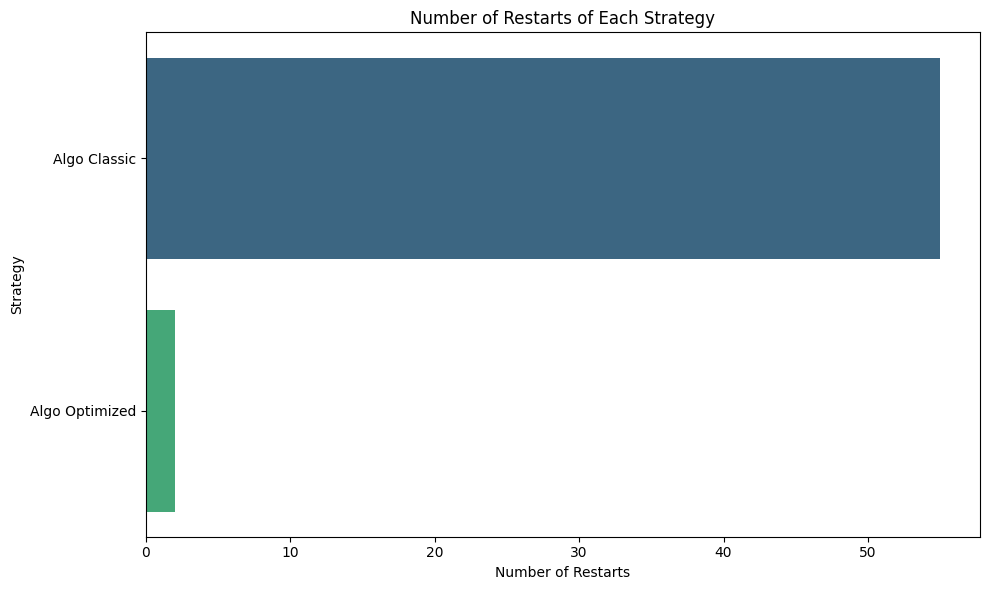

In [47]:
# Barplot of the number of restarts of each strategy
n_restarts = {
    'Algo Classic': algo_classic.n_restart(),
    'Algo Optimized': algo_opti.n_restart(),
}
n_restarts_df = pd.DataFrame(list(n_restarts.items()), columns=['Strategy', 'Number of Restarts'])
n_restarts_df = n_restarts_df.sort_values(by='Number of Restarts', ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='Number of Restarts', y='Strategy', data=n_restarts_df, palette='viridis')
ax.set_title("Number of Restarts of Each Strategy")
plt.tight_layout()
plt.show()

### Blest

In [48]:
# 2) Initialize capital arrays
capital_classic     = np.zeros(Tw); capital_classic[0]     = 1.0
capital_opti        = np.zeros(Tw); capital_opti[0]        = 1.0
capital_uniform     = np.zeros(Tw); capital_uniform[0]     = 1.0
capital_restart1y   = np.zeros(Tw); capital_restart1y[0]   = 1.0  # curva anual

# 3) Instantiate algorithms
algo_classic    = VB_FTRL(
    n_assets,
    mu=0.2,
    lambda_val=0.2,
    threshold=-0.2,
    corr_func=blest_coeff,
    scoring_func=scoring.historic_returns
)
algo_opti       = VB_FTRL(
    n_assets,
    mu=0.01,
    lambda_val=0.12,
    threshold=-0.30078125,
    corr_func=blest_coeff,
    scoring_func=scoring.historic_returns
)
algo_restart1y  = VB_FTRL(
    n_assets,
    mu=0.2,
    lambda_val=0.2,
    threshold=-1.0,                   # sin reinicios automáticos
    corr_func=blest_coeff,
    scoring_func=scoring.historic_returns
)

# 4) Keep track of weights for plotting
pastw_classic   = [algo_classic.w.copy()]
pastw_opti      = [algo_opti.w.copy()]
pastw_restart1y = [algo_restart1y.w.copy()]

# 5) Weekly backtest loop
semanas_por_1y = 52  # aprox. 1 año en semanas

for t in range(T):
    # actual return vector
    r = R[t]
    r_rescaled = R_rescaled[t]

    # Uniform strategy
    capital_uniform[t + 1] = capital_uniform[t] * (np.sum(r + 1) / n_assets)

    # Classic algorithm
    w_classic = algo_classic.w.copy()
    capital_classic[t + 1] = capital_classic[t] * np.dot(w_classic, (r + 1))
    algo_classic.update(r_rescaled)
    algo_classic.w[algo_classic.w < 0] = 0.1
    algo_classic.w /= np.linalg.norm(algo_classic.w, 1)
    pastw_classic.append(algo_classic.w.copy())

    # Optimized algorithm
    w_opti = algo_opti.w.copy()
    capital_opti[t + 1] = capital_opti[t] * np.dot(w_opti, (r + 1))
    algo_opti.update(r_rescaled)
    algo_opti.w[algo_opti.w < 0] = 0.1
    algo_opti.w /= np.linalg.norm(algo_opti.w, 1)
    pastw_opti.append(algo_opti.w.copy())

    # --- Algoritmo que reinicia cada 1 año (52 semanas) ---
    if (t > 0) and (t % semanas_por_1y == 0):
        prev_index = t - 1
        prev_return = R[prev_index]
        algo_restart1y.restart(prev_return, prev_index)
        # Sobrescribir el peso en la iteración t con el peso recién reiniciado
        pastw_restart1y[t] = algo_restart1y.w.copy()

    # Calcular capital para restart1y usando el peso actual
    w_r1 = algo_restart1y.w.copy()
    capital_restart1y[t + 1] = capital_restart1y[t] * np.dot(w_r1, (r + 1))

    # Actualizar algoritmo restart1y para la próxima semana
    algo_restart1y.update(r_rescaled)
    algo_restart1y.w[algo_restart1y.w < 0] = 0.1
    algo_restart1y.w /= np.linalg.norm(algo_restart1y.w, 1)
    pastw_restart1y.append(algo_restart1y.w.copy())


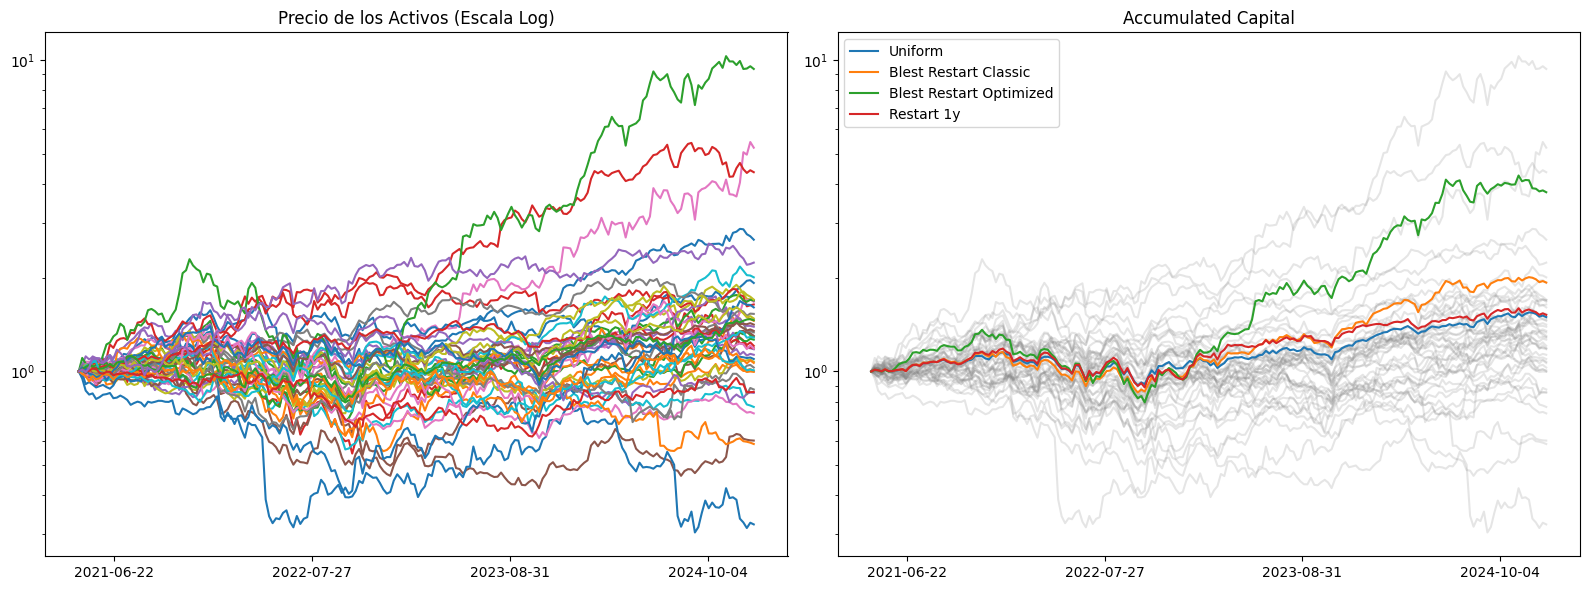

In [49]:
# 6) Plotting
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Asset prices (log scale)
axes[0].plot(testing_data.index, testing_data.values)
axes[0].set_title("Precio de los Activos (Escala Log)")
axes[0].set_yscale('log')
axes[0].xaxis.set_major_locator(MaxNLocator(nbins=5))

# Cumulative capital
axes[1].plot(testing_data.index, testing_data.values, color='gray', alpha=0.2)
axes[1].plot(testing_data.index, capital_uniform, label='Uniform')
axes[1].plot(testing_data.index, capital_classic, label='Blest Restart Classic')
axes[1].plot(testing_data.index, capital_opti, label='Blest Restart Optimized')
axes[1].plot(testing_data.index, capital_restart1y, label='Restart 1y')
axes[1].set_title("Accumulated Capital")
axes[1].set_yscale('log')
axes[1].legend()
axes[1].xaxis.set_major_locator(MaxNLocator(nbins=5))

plt.tight_layout()
plt.show()


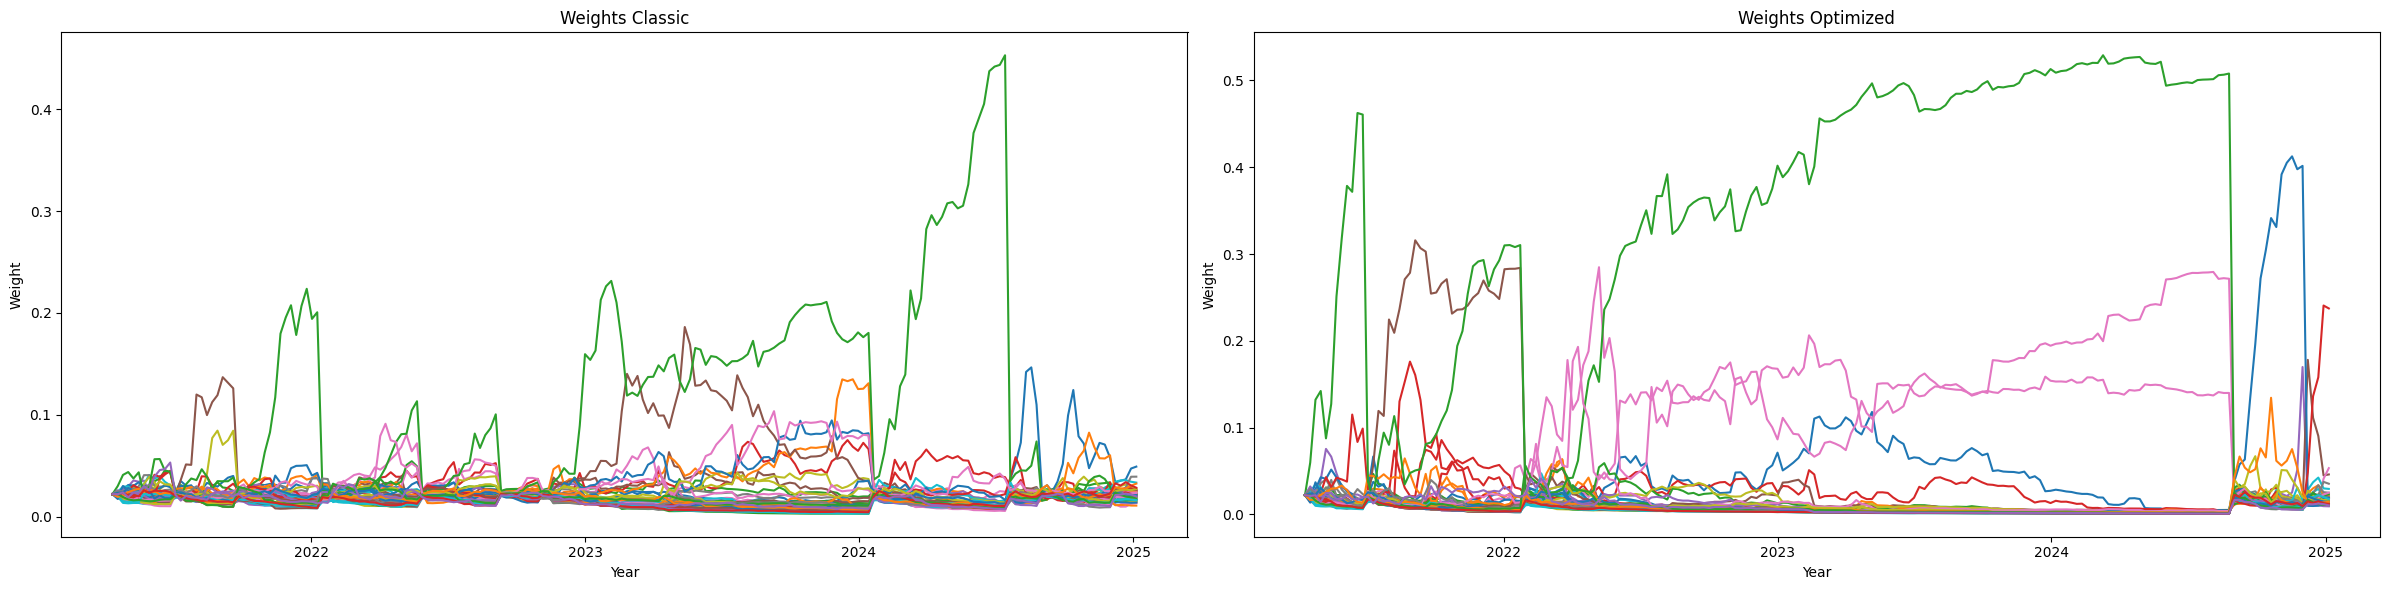

In [50]:
import matplotlib.dates as mdates

# Convert weight histories to NumPy arrays
weights_classic = np.array(pastw_classic)
weights_opti    = np.array(pastw_opti)

# Use the same weekly index from testing_data for the x-axis
dates = testing_data.index[:len(weights_classic)]

fig, axes = plt.subplots(1, 2, figsize=(24, 6), sharex=True)

# — Left subplot: Weights Classic
axes[0].plot(dates, weights_classic)
axes[0].set_title("Weights Classic")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Weight")
axes[0].xaxis.set_major_locator(mdates.YearLocator())
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.setp(axes[0].get_xticklabels(), rotation=0, ha='center')

# — Right subplot: Weights Optimized
axes[1].plot(dates, weights_opti)
axes[1].set_title("Weights Optimized")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Weight")
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.setp(axes[1].get_xticklabels(), rotation=0, ha='center')

plt.tight_layout()
plt.show()


C:\Users\Javier Toro B\AppData\Local\Temp\ipykernel_8296\1144233905.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Final Capital', y='Strategy', data=final_capital_df, palette='viridis')


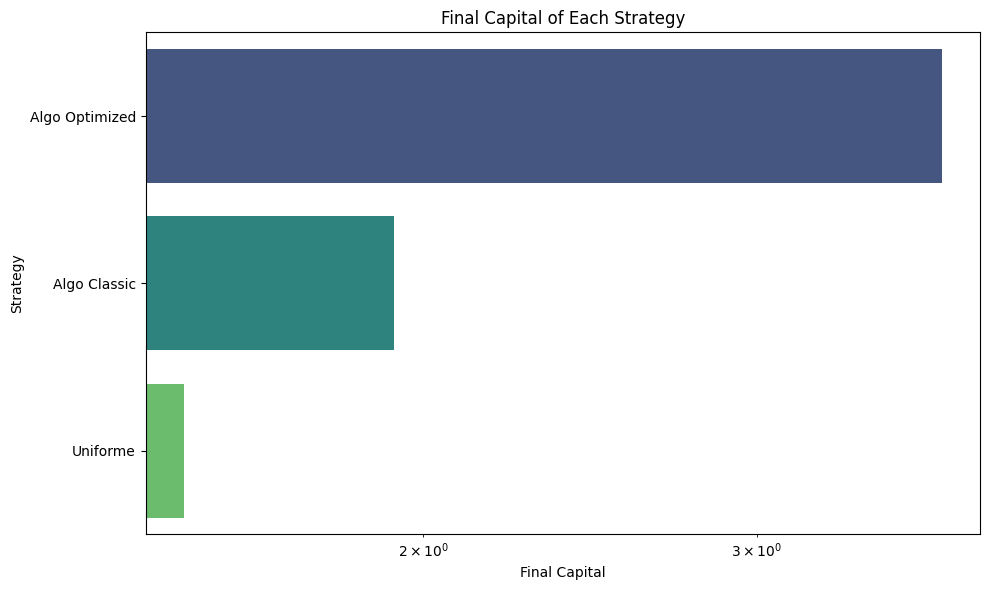

In [51]:
# barplot of the number of the final capital of each strategy
final_capital = {
    'Algo Classic': capital_classic[-1],
    'Algo Optimized': capital_opti[-1],
    'Uniforme': capital_uniform[-1]
}
final_capital_df = pd.DataFrame(list(final_capital.items()), columns=['Strategy', 'Final Capital'])
final_capital_df = final_capital_df.sort_values(by='Final Capital', ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='Final Capital', y='Strategy', data=final_capital_df, palette='viridis')
ax.set_title("Final Capital of Each Strategy")
ax.set_xscale('log')
plt.tight_layout()
plt.show()

C:\Users\Javier Toro B\AppData\Local\Temp\ipykernel_8296\717368826.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Number of Restarts', y='Strategy', data=n_restarts_df, palette='viridis')


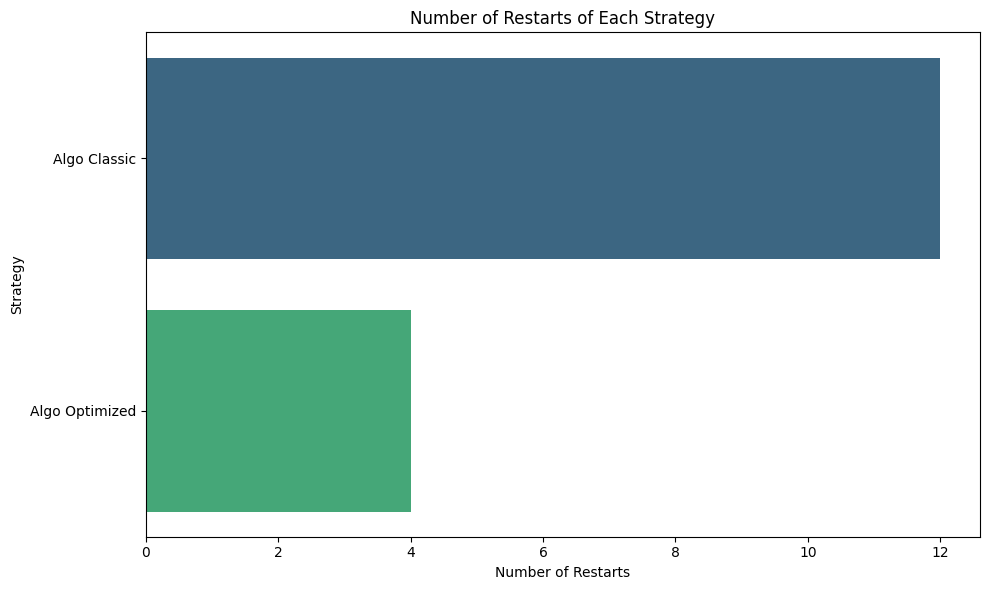

In [52]:
# Barplot of the number of restarts of each strategy
n_restarts = {
    'Algo Classic': algo_classic.n_restart(),
    'Algo Optimized': algo_opti.n_restart(),
}
n_restarts_df = pd.DataFrame(list(n_restarts.items()), columns=['Strategy', 'Number of Restarts'])
n_restarts_df = n_restarts_df.sort_values(by='Number of Restarts', ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='Number of Restarts', y='Strategy', data=n_restarts_df, palette='viridis')
ax.set_title("Number of Restarts of Each Strategy")
plt.tight_layout()
plt.show()

## Comparison between the three methods

In [53]:
# 2) Initialize capital arrays
capital_tau          = np.zeros(Tw); capital_tau[0]          = 1.0
capital_wtau         = np.zeros(Tw); capital_wtau[0]         = 1.0
capital_blest        = np.zeros(Tw); capital_blest[0]        = 1.0
capital_no_restart   = np.zeros(Tw); capital_no_restart[0]   = 1.0
capital_uniform      = np.zeros(Tw); capital_uniform[0]      = 1.0
capital_restart1y    = np.zeros(Tw); capital_restart1y[0]    = 1.0  # curva anual

# 3) Instantiate algorithms
algo_tau           = VB_FTRL(n_assets, mu=0.01, lambda_val=0.12, threshold=-0.6,         scoring_func=scoring.historic_returns)
algo_wtau          = VB_FTRL(n_assets, mu=0.01, lambda_val=0.12, threshold=-0.7375,      corr_func=weightedtau, scoring_func=scoring.historic_returns)
algo_blest         = VB_FTRL(n_assets, mu=0.01, lambda_val=0.12, threshold=-0.30078125, corr_func=blest_coeff, scoring_func=scoring.historic_returns)
algo_no_restart    = VB_FTRL(n_assets, mu=0.2, lambda_val=0.2, threshold=-1.0,         scoring_func=scoring.historic_returns)  # sin reinicios automáticos
algo_restart1y     = VB_FTRL(n_assets, mu=0.01, lambda_val=0.12, threshold=-1.0,         scoring_func=scoring.historic_returns)  # reinicios manuales anuales

# 4) Keep track of weights for plotting
pastw_tau          = [algo_tau.w.copy()]
pastw_wtau         = [algo_wtau.w.copy()]
pastw_blest        = [algo_blest.w.copy()]
pastw_no_restart   = [algo_no_restart.w.copy()]
pastw_restart1y    = [algo_restart1y.w.copy()]  # lista de pesos para reinicio anual

# 5) Weekly backtest loop
semanas_por_1y = 52  # ≈ 1 año en semanas

for t in range(T):
    # actual return vector
    r = R[t]
    r_rescaled = R_rescaled[t]

    # 5a) Uniform strategy
    capital_uniform[t + 1] = capital_uniform[t] * (np.sum(r + 1) / n_assets)

    # 5b) Algoritmo sin reinicio
    w_no_restart = algo_no_restart.w.copy()
    capital_no_restart[t + 1] = capital_no_restart[t] * np.dot(w_no_restart, (r + 1))
    algo_no_restart.update(r_rescaled)
    algo_no_restart.w[algo_no_restart.w < 0] = 0.1
    algo_no_restart.w /= np.linalg.norm(algo_no_restart.w, 1)
    pastw_no_restart.append(algo_no_restart.w.copy())

    # 5c) Kendall algorithm
    w_tau = algo_tau.w.copy()
    capital_tau[t + 1] = capital_tau[t] * np.dot(w_tau, (r + 1))
    algo_tau.update(r_rescaled)
    algo_tau.w[algo_tau.w < 0] = 0.1
    algo_tau.w /= np.linalg.norm(algo_tau.w, 1)
    pastw_tau.append(algo_tau.w.copy())

    # 5d) Weighted Kendall algorithm
    w_wtau = algo_wtau.w.copy()
    capital_wtau[t + 1] = capital_wtau[t] * np.dot(w_wtau, (r + 1))
    algo_wtau.update(r_rescaled)
    algo_wtau.w[algo_wtau.w < 0] = 0.1
    algo_wtau.w /= np.linalg.norm(algo_wtau.w, 1)
    pastw_wtau.append(algo_wtau.w.copy())

    # 5e) Blest algorithm
    w_blest = algo_blest.w.copy()
    capital_blest[t + 1] = capital_blest[t] * np.dot(w_blest, (r + 1))
    algo_blest.update(r_rescaled)
    algo_blest.w[algo_blest.w < 0] = 0.1
    algo_blest.w /= np.linalg.norm(algo_blest.w, 1)
    pastw_blest.append(algo_blest.w.copy())

    # 5f) Algoritmo con reinicio cada 1 año (52 semanas)
    if (t > 0) and (t % semanas_por_1y == 0):
        prev_index = t - 1
        prev_return = R[prev_index]
        algo_restart1y.restart(prev_return, prev_index)
        pastw_restart1y[t] = algo_restart1y.w.copy()

    w_r1 = algo_restart1y.w.copy()
    capital_restart1y[t + 1] = capital_restart1y[t] * np.dot(w_r1, (r + 1))
    algo_restart1y.update(r_rescaled)
    algo_restart1y.w[algo_restart1y.w < 0] = 0.1
    algo_restart1y.w /= np.linalg.norm(algo_restart1y.w, 1)
    pastw_restart1y.append(algo_restart1y.w.copy())


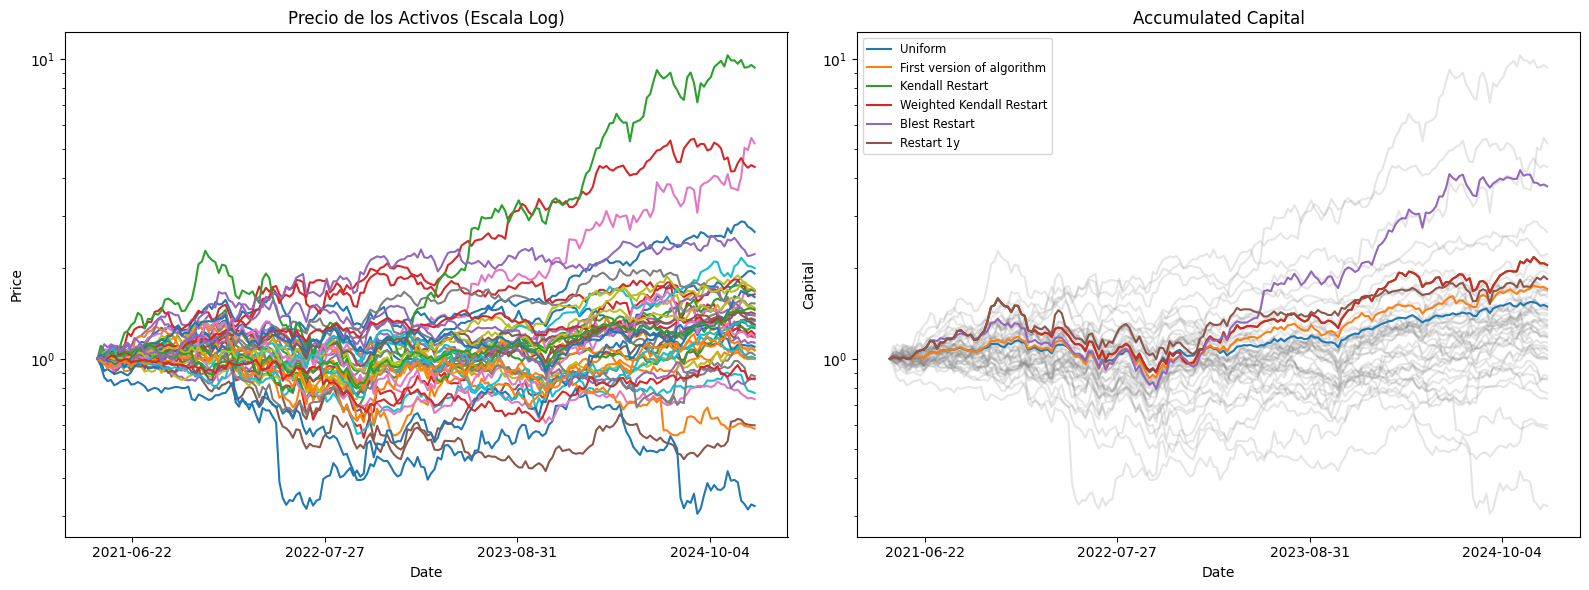

In [54]:
# 6) Plotting
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Asset prices (log scale)
axes[0].plot(testing_data.index, testing_data.values)
axes[0].set_title("Precio de los Activos (Escala Log)")
axes[0].set_yscale('log')
axes[0].xaxis.set_major_locator(MaxNLocator(nbins=5))
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Price")

# Cumulative capital
axes[1].plot(testing_data.index, testing_data.values, color='gray', alpha=0.2)
axes[1].plot(testing_data.index, capital_uniform,        label='Uniform')
axes[1].plot(testing_data.index, capital_no_restart,     label='First version of algorithm')
axes[1].plot(testing_data.index, capital_tau,            label='Kendall Restart')
axes[1].plot(testing_data.index, capital_wtau,           label='Weighted Kendall Restart')
axes[1].plot(testing_data.index, capital_blest,          label='Blest Restart')
axes[1].plot(testing_data.index, capital_restart1y,      label='Restart 1y')
axes[1].set_title("Accumulated Capital")
axes[1].set_yscale('log')
axes[1].xaxis.set_major_locator(MaxNLocator(nbins=5))
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Capital")
axes[1].legend(fontsize='small')

plt.tight_layout()
plt.show()


In [ ]:
# Elegir mejor los activos para demostrar bien que el algoritmo reinicia cuando tiene que reiniciar, por ejemplo, el covid.
# Saber explicarlo de manera clara, explicar el intéres de hacerlo, por qué lo hacemos y cómo lo hacemos. Cómo llegamos a los resultados que tenemos.

C:\Users\Javier Toro B\AppData\Local\Temp\ipykernel_8296\743556600.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Final Capital', y='Strategy', data=final_capital_df, palette='viridis')


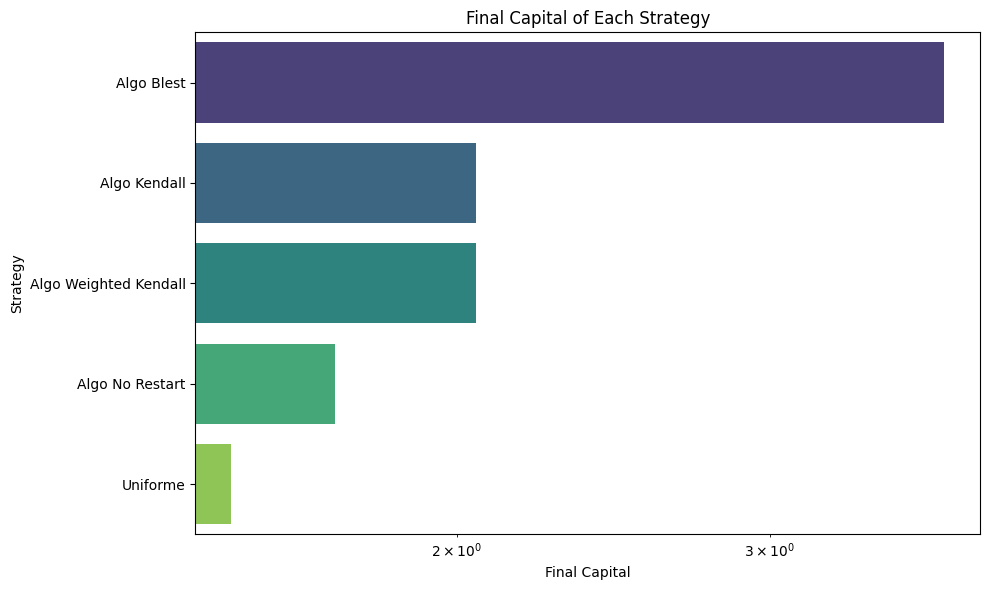

In [55]:
# We do a bar plot of the final capital of each strategy
final_capital = {
    'Algo Kendall': capital_tau[-1],
    'Algo Weighted Kendall': capital_wtau[-1],
    'Algo Blest': capital_blest[-1],
    'Uniforme': capital_uniform[-1],
    'Algo No Restart': capital_no_restart[-1]
}
final_capital_df = pd.DataFrame(list(final_capital.items()), columns=['Strategy', 'Final Capital'])
final_capital_df = final_capital_df.sort_values(by='Final Capital', ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='Final Capital', y='Strategy', data=final_capital_df, palette='viridis')
ax.set_title("Final Capital of Each Strategy")
ax.set_xscale('log')
plt.tight_layout()
plt.show()

C:\Users\Javier Toro B\AppData\Local\Temp\ipykernel_8296\3575330573.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


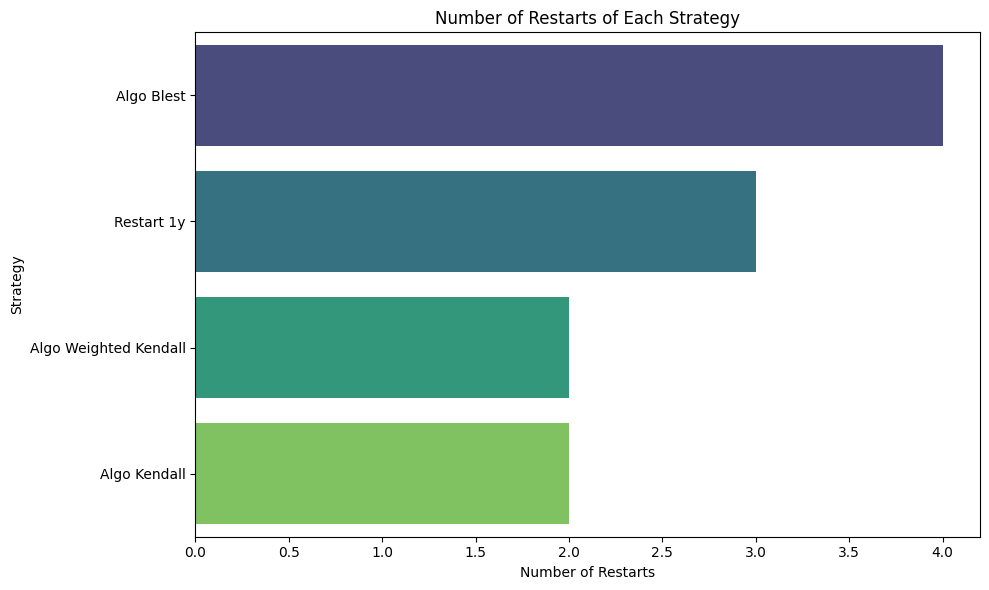

In [56]:
# Bar plot of the number of restarts of each strategy

# Calculate the number of annual restarts manually
n_restart_1y = T // 52

n_restarts = {
    'Algo Kendall': algo_tau.n_restart(),
    'Algo Weighted Kendall': algo_wtau.n_restart(),
    'Algo Blest': algo_blest.n_restart(),
    'Restart 1y': n_restart_1y
}

n_restarts_df = pd.DataFrame(
    list(n_restarts.items()),
    columns=['Strategy', 'Number of Restarts']
)
n_restarts_df = n_restarts_df.sort_values(
    by='Number of Restarts',
    ascending=False
)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    x='Number of Restarts',
    y='Strategy',
    data=n_restarts_df,
    palette='viridis',
    ax=ax
)
ax.set_title("Number of Restarts of Each Strategy")
plt.tight_layout()
plt.show()


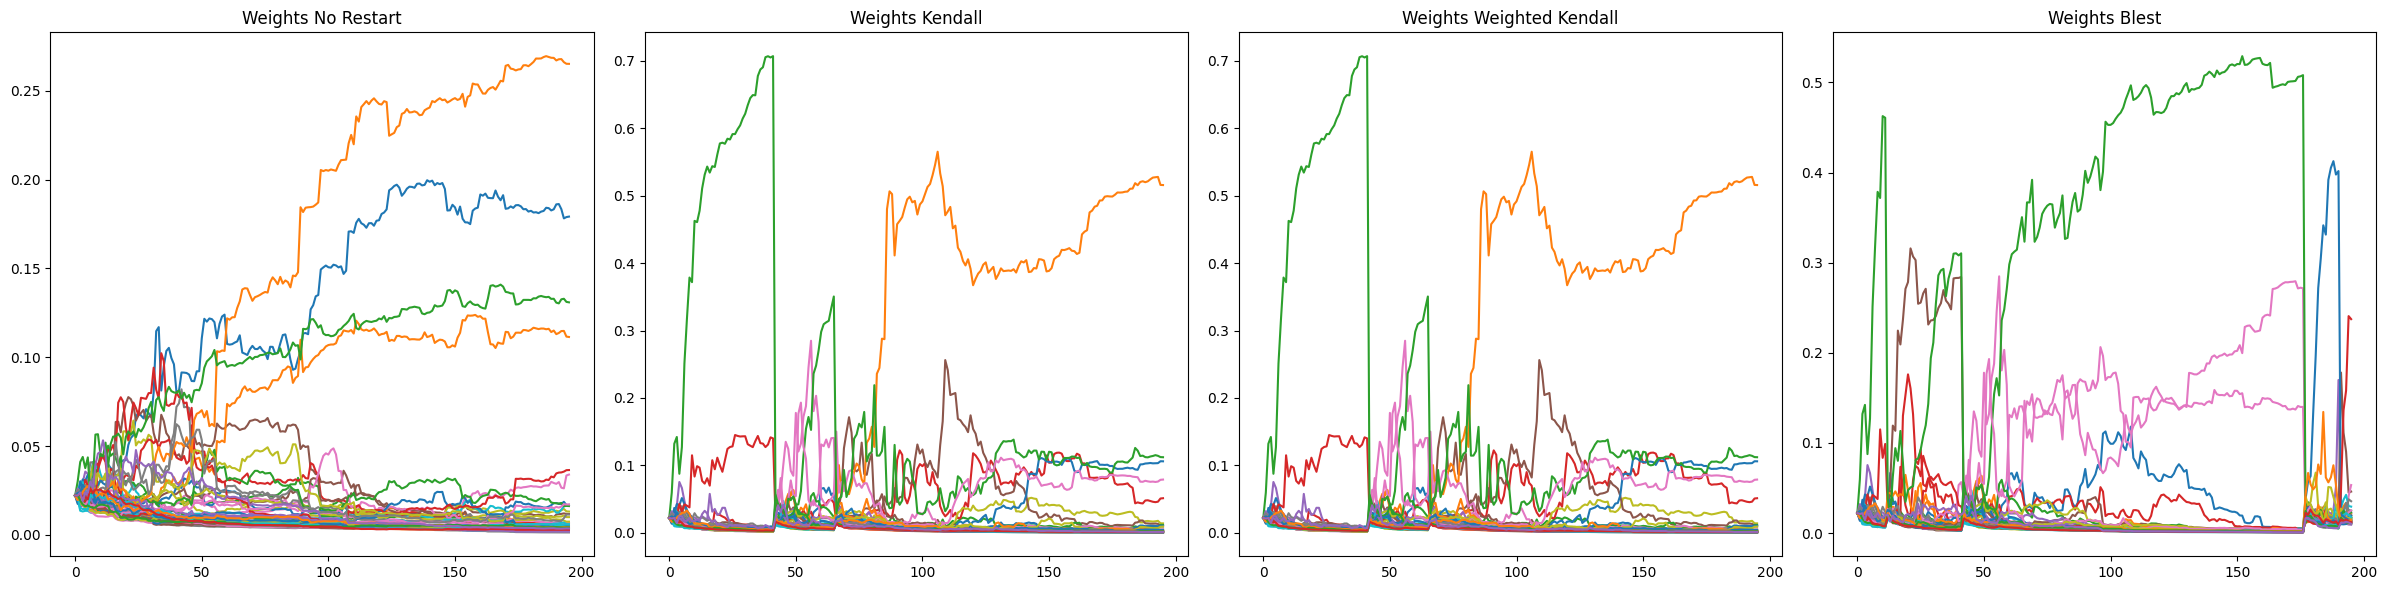

In [57]:
# PONER LAS FECHAS EN EL EJE X DE LOS PRECIOS DE LOS ACTIVOS
# We plot the weights of the algorithms
fig, axes = plt.subplots(1, 4, figsize=(24,6))
# Weights Kendall
axes[1].plot(pd.Index(range(len(pastw_tau))), np.array(pastw_tau))
axes[1].set_title("Weights Kendall")
axes[1].xaxis.set_major_locator(MaxNLocator(nbins=5))
# Weights weighted Kendall
axes[2].plot(pd.Index(range(len(pastw_wtau))), np.array(pastw_wtau))
axes[2].set_title("Weights Weighted Kendall")
axes[2].xaxis.set_major_locator(MaxNLocator(nbins=5))
# Weights Blest
axes[3].plot(pd.Index(range(len(pastw_blest))), np.array(pastw_blest))
axes[3].set_title("Weights Blest")
axes[3].xaxis.set_major_locator(MaxNLocator(nbins=5))
# Weights No Restart
axes[0].plot(pd.Index(range(len(pastw_no_restart))), np.array(pastw_no_restart))
axes[0].set_title("Weights No Restart")
axes[0].xaxis.set_major_locator(MaxNLocator(nbins=5))
plt.tight_layout()
plt.show()